# Case Study 13 — Is a Machine-Learning Model Worth It?

**Using statistics to decide between a simple model, a better-specified statistical model and a non-linear ML model**

| | |
|---|---|
| **Domain** | Credit cards: application scoring (credit risk) |
| **Stakeholders** | Chief Risk Officer (decision owner), Head of Credit Policy, Model Risk Management, ML team |
| **Difficulty** | Advanced |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | 02 (two-group & categorical tests), 05 (correlation), 07/09 (multiple regression, VIF), 11 (logistic regression), 12 (classification metrics) |
| **Data** | ~40,000 approved card applications (Jan-2023 to Dec-2024) with 12-month outcome; numerical, ordinal and nominal columns |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. Because we know the true data-generating process (`src/generate_data.py`), we can check whether
> each statistical test led us to the right modelling decision.

**What you will learn**

1. How to frame "should we use ML?" as a set of **testable statistical questions**, not a matter of taste.
2. How to screen **numerical, ordinal and nominal** predictors with the right test for each type, and control false
   discoveries.
3. Why **low correlation does not mean low predictive value**, and how to detect non-linear signal (mutual
   information, binned log-odds, likelihood-ratio tests for splines).
4. How to test **non-linearity, interactions, ordinal coding and multicollinearity** inside a statistical model.
5. How to **compare models properly**: repeated cross-validation with the **corrected resampled t-test**, the
   **DeLong** test, **bootstrap** CIs, **McNemar's** test, calibration, out-of-time validation, PSI and learning
   curves.
6. How to turn an AUC difference into **money**, and weigh it against the cost and risk of ML.
7. A **decision playbook**: for every test outcome, what to do next. A **scenario lab** shows the playbook working in
   four different "worlds" (linear, strongly non-linear, no signal, small data).

## Section 1 — Business context

You are a senior data scientist in the **Credit Risk Analytics** team of a credit-card issuer. Applications are
approved with an in-house **logistic-regression scorecard** that has been in production for three years.

The **ML team** has built a gradient-boosting model and circulated a one-pager:

> *"Our XGBoost-style model reaches **AUC 0.93** versus **0.78** for the current scorecard on a held-out 20% sample.
> We recommend replacing the scorecard next quarter."*

The **Chief Risk Officer** forwards it to you:

> *"This looks too good to be true. Before I take it to the Model Risk Committee I need an independent view. Is the
> improvement real? Is it big enough to matter in money? Would it hold up on new customers? And could we get the same
> benefit with a better version of our existing scorecard, which the regulator and our credit officers already
> understand? Please give me a recommendation I can defend: ML, improved scorecard, or no change."*

**Why the CRO is cautious.** A gradient-boosting model in credit decisions brings real costs: model-risk validation,
explainability for adverse-action reasons and regulatory review, monitoring infrastructure, and retraining
discipline. A credit-risk team would budget roughly ₹45 lakh a year more than for a scorecard. ML is worth it only if
the **incremental, reliable** gain clearly exceeds that.

## Section 2 — Business questions

1. Is the data fit for modelling? Is anything in it unusable at application time?
2. Which applicant characteristics carry real risk information, and which are noise or proxies?
3. Are the relationships simple (linear), or curved, threshold-like or interacting, the situations where ML usually helps?
4. How much better does each candidate model really predict on **future** applicants?
5. Is the difference between models **statistically real**, and is it **worth the money**?
6. Which model should go to the Model Risk Committee, and under what conditions would the answer change?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Data fit? Unusable fields? | Data quality; **target leakage** (information not available at decision time) | Rule checks, timing review, single-feature AUC screen |
| 2 | Which characteristics matter? | Is each predictor associated with default? Controlling false discoveries | Numeric: Mann-Whitney + univariate AUC + Spearman; ordinal: Spearman / trend test; nominal: χ² + Cramér's V; **mutual information**; **Benjamini-Hochberg FDR** |
| 2b | Real or proxy? | Is the association still there **after controlling for other variables**? | Likelihood-ratio tests (LRT) of dropping each predictor from a multivariable logistic model |
| 3 | Simple or complex shapes? | Is the effect linear in the log-odds? Do pairs of variables interact? Is an ordinal variable linear across its levels? | **LRT: linear vs spline**, **LRT for pre-specified interactions** (Holm-adjusted), **LRT: ordinal trend vs categories**, binned log-odds plots |
| 3b | Redundant inputs? | Multicollinearity | Correlation matrix, **VIF** |
| 4 | Real predictive gain? | Out-of-sample discrimination, calibration, stability | Repeated stratified CV, **out-of-time (OOT)** test, ROC-AUC, PR-AUC, Brier score, calibration slope, **PSI** |
| 5 | Statistically real? Worth it? | Is AUC(B) − AUC(A) ≠ 0? Is the value gain > cost? | **Corrected resampled t-test**, **DeLong**, **bootstrap CI**, **McNemar**; value simulation with bootstrap CI |
| 6 | When would the answer change? | Sensitivity to data size and world structure | **Learning curves**, **scenario lab** |

**The model ladder.** We compare four models of increasing complexity, so that each step's gain can be tested
separately:

| Model | Description | Interpretability |
|---|---|---|
| **M0 Current scorecard** | Logistic regression on the 6 variables in production today, entered linearly | High |
| **M1 Full linear logistic** | All valid predictors, linear terms, one-hot nominal variables | High |
| **M2 Statistically-specified GLM** | Logistic regression with **splines, interactions and codings chosen by the tests in Sections 9–10** | High (still a scorecard) |
| **M3 Gradient boosting (ML)** | Histogram gradient boosting with native categorical handling, tuned by CV | Low (needs SHAP-type tooling) |

> **Fair comparison principle.** ML models are often compared against a *lazy* statistical baseline. A fair test gives
> the statistical model the same care (feature engineering guided by tests) that the ML model gets in tuning. **M2,
> not M0, is the real competitor to M3.**

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.contingency_tables import Table, mcnemar

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from sklearn.feature_selection import mutual_info_classif
from sklearn.calibration import calibration_curve

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED
from statistical_tests import proportion_ci, delong_test, corrected_resampled_ttest, psi

CASE_DIR = ROOT / "case_studies" / "13_is_ml_worth_it"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=RuntimeWarning)       # log(0) inside binned plots
rng = rng_for_case(1313)
SEED = 13

# Business parameters (Finance / Credit Policy)
LOSS_PER_BAD = 60_000          # ₹ expected loss when an approved customer goes bad (exposure × LGD)
PROFIT_PER_GOOD = 4_500        # ₹ annual net profit from a good customer
DECLINE_RATE = 0.15            # policy: decline the riskiest 15% of applicants
APPS_PER_YEAR = 200_000        # applications scored per year
ML_EXTRA_COST_LAKH = 45        # ₹ lakh / year: extra cost of running an ML model in production
GLM_UPGRADE_COST_LAKH = 6      # ₹ lakh one-off: upgrading the scorecard within existing infrastructure

## Section 4 — Load the data

In [2]:
raw = pd.read_csv(PATHS["data"] / "card_applications.csv")
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

COLUMN_TYPES = {
    "identifier/time": ["application_id", "application_month"],
    "numerical": ["age", "monthly_income", "bureau_score", "credit_utilization", "enquiries_6m",
                  "months_since_delinquency", "dti", "years_at_employer", "num_credit_cards", "requested_limit"],
    "ordinal": ["education", "city_tier", "income_verification"],
    "nominal": ["occupation", "residence_type", "acquisition_channel", "state", "marital_status"],
    "post-outcome (check!)": ["collections_contact_flag"],
    "target": ["bad_12m"],
}
pd.DataFrame([(t, c, str(raw[c].dtype), raw[c].nunique(), raw[c].isna().mean())
              for t, cols in COLUMN_TYPES.items() for c in cols],
             columns=["type", "column", "dtype", "n_unique", "share_missing"])

40,025 rows × 22 columns


,application_id,application_month,age,monthly_income,bureau_score,credit_utilization,enquiries_6m,months_since_delinquency,dti,years_at_employer,num_credit_cards,requested_limit,education,city_tier,income_verification,occupation,residence_type,acquisition_channel,state,marital_status,collections_contact_flag,bad_12m
0,CC5026002,2024-06,37,"89,200.0000",NaN,NaN,1,NaN,0.1950,1.7000,0,"168,000.0000",Graduate,Tier-1,Self-declared,Salaried-Private,Family,DSA,Karnataka,Single,1,0
1,CC5021983,2023-05,42,"38,100.0000",755.0000,0.2420,2,NaN,0.2210,0.6000,0,"86,000.0000",Postgraduate,Tier-1,Self-declared,Gig/Freelance,Rented,Branch,Karnataka,Married,0,0
2,CC5005004,2024-06,20,"55,900.0000",633.0000,0.2950,2,NaN,0.3720,3.1000,0,"281,000.0000",Graduate,Tier-2,Payslip,Salaried-Private,Family,Online-Aggregator,Kerala,Single,0,0
3,CC5021173,2024-02,21,"26,300.0000",701.0000,0.4530,2,NaN,0.2300,1.4000,1,"105,000.0000",Postgraduate,Tier-1,Payslip,Gig/Freelance,Owned,DSA,Maharashtra,Married,0,0
4,CC5015314,2023-01,36,"58,500.0000",707.0000,0.2950,2,NaN,0.2940,1.5000,2,"72,000.0000",Graduate,Metro,Self-declared,Salaried-Private,Rented,Online-Aggregator,Kerala,Married,0,0


,type,column,dtype,n_unique,share_missing
0,identifier/time,application_id,str,40000,0.0000
1,identifier/time,application_month,str,24,0.0000
2,numerical,age,int64,60,0.0000
3,numerical,monthly_income,float64,2031,0.0000
4,numerical,bureau_score,float64,385,0.0641
5,numerical,credit_utilization,float64,981,0.0641
6,numerical,enquiries_6m,int64,12,0.0000
7,numerical,months_since_delinquency,float64,59,0.8993
8,numerical,dti,float64,830,0.0000
9,numerical,years_at_employer,float64,223,0.0000


**Why column type drives method choice.**

| Type | Examples | Meaning of the values | Right association tests | Encoding in a GLM | Encoding in GBM |
|---|---|---|---|---|---|
| **Numerical** | income, utilisation, enquiries | Quantities. Differences are meaningful | Mann-Whitney / t-test, point-biserial / Spearman, univariate AUC, mutual information | Linear, log, spline, bins | As-is (trees are invariant to monotone transforms) |
| **Ordinal** | education, city tier, verification level | Ordered categories. Order meaningful, spacing not | Spearman / trend (linear-by-linear) test, χ² | Integer score **if** the trend is linear (tested), else dummies | Integer codes (order preserved) |
| **Nominal** | occupation, channel, state | Unordered labels | χ² test of independence, Cramér's V | One-hot (reference category) | Native categorical or one-hot; target encoding only inside CV |

Mistakes that cost money in practice: treating a nominal code as a number ("state = 7"), dummy-coding an ordinal
variable whose effect is genuinely linear (wastes degrees of freedom), and forcing a linear score on an ordinal
variable whose effect is not monotone.

## Section 5 — Data quality and leakage

### 5.1 Standard checks

In [3]:
df = raw.copy()
report = {}
report["exact duplicate rows"] = int(df.duplicated().sum())
df = df.drop_duplicates()
report["occupation labels before cleaning"] = df["occupation"].nunique()
df["occupation"] = (df["occupation"].str.strip().str.replace(" - ", "-", regex=False).str.lower()
                    .str.replace("salaried-private", "Salaried-Private").str.replace("salaried-govt", "Salaried-Govt")
                    .str.replace("self-employed-professional", "Self-employed-Professional")
                    .str.replace("self-employed-business", "Self-employed-Business")
                    .str.replace("gig/freelance", "Gig/Freelance").str.replace("student", "Student").str.replace("retired", "Retired"))
report["occupation labels after cleaning"] = df["occupation"].nunique()
report["impossible ages (<18 or >80)"] = int((~df["age"].between(18, 80)).sum())
report["non-positive incomes"] = int((df["monthly_income"] <= 0).sum())
df = df[df["age"].between(18, 80) & (df["monthly_income"] > 0)].copy()
report["rows after cleaning"] = len(df)
report["bad rate"] = round(df["bad_12m"].mean(), 4)
display(pd.Series(report, name="value").to_frame())
print("Missing values (share):")
df.isna().mean()[lambda s: s > 0].round(3)

,value
exact duplicate rows,25.0000
occupation labels before cleaning,21.0000
occupation labels after cleaning,7.0000
impossible ages (<18 or >80),9.0000
non-positive incomes,6.0000
rows after cleaning,"39,985.0000"
bad rate,0.0805


Missing values (share):


bureau_score               0.0640
credit_utilization         0.0640
months_since_delinquency   0.8990
dtype: float64

- **Duplicates, label variants, impossible ages and negative incomes** are fixed or removed (fewer than 0.2% of rows).
  An ML model would have quietly treated `"salaried - private"` as a separate occupation.
- **Missing values are structural, not random**:
  - `bureau_score` and `credit_utilization` are blank for **no-hit** applicants (no bureau history). We create a
    `no_hit` flag and fill the blanks with the median. The flag carries the information, and the filled value is a
    placeholder the flag "switches off".
  - `months_since_delinquency` is blank for applicants **never delinquent**. That is the best possible value, not an
    unknown one. Imputing a median would invent delinquencies. We create `ever_delinquent` and
    `recent_delinquency` (< 12 months) flags instead.

### 5.2 Target leakage: the most important check in any ML project

**Leakage** means a feature contains information that would **not be available at the moment the prediction is
used**, typically because it is recorded *after* the outcome starts to happen. Leakage produces spectacular test
scores and useless production models.

Two warning signs: a single feature that predicts the target almost perfectly, and a feature whose timing is after
the decision date.

In [4]:
def single_feature_auc(x, y):
    x = pd.Series(x).fillna(pd.Series(x).median())
    a = roc_auc_score(y, x)
    return max(a, 1 - a)          # direction-free

screen = pd.Series({c: single_feature_auc(df[c], df["bad_12m"])
                    for c in COLUMN_TYPES["numerical"] + COLUMN_TYPES["post-outcome (check!)"]}).sort_values(ascending=False)
display(screen.to_frame("single-feature AUC").style.format("{:.3f}").bar(color="#cde2fb", vmin=0.5, vmax=1))
print(pd.crosstab(df["collections_contact_flag"], df["bad_12m"], normalize="columns").round(3))

,single-feature AUC
collections_contact_flag,0.913
bureau_score,0.690
monthly_income,0.661
requested_limit,0.641
num_credit_cards,0.638
dti,0.613
enquiries_6m,0.574
age,0.553
credit_utilization,0.546
years_at_employer,0.537


bad_12m                       0      1
collections_contact_flag              
0                        0.9740 0.1480
1                        0.0260 0.8520


`collections_contact_flag` alone has an AUC of about **0.91**, far above any genuine application variable (the best,
bureau score, is about 0.69). The data dictionary confirms the reason: the flag is set when the **collections team
contacts a customer**, which happens *after* the account opens and mostly *because* the customer is already in
arrears. At application time it does not exist.

**Decision: remove it.** This is almost certainly where the ML team's "AUC 0.93" came from. We reproduce that claim
in Section 11.1.

> **Leakage checklist:** (1) single-feature AUC > ~0.90 or a near-perfect χ² association; (2) any field updated after
> the decision date; (3) fields derived from the target (e.g., "write-off amount"); (4) IDs or timestamps that encode
> outcome processing; (5) features computed over a window that overlaps the outcome window.

In [5]:
ORD_LEVELS = {"education": ["Below 12th", "12th pass", "Graduate", "Postgraduate"],
              "city_tier": ["Tier-3", "Tier-2", "Tier-1", "Metro"],
              "income_verification": ["Self-declared", "Payslip", "Bank statement"]}
SELF_EMP = ["Self-employed-Professional", "Self-employed-Business", "Gig/Freelance"]

def add_features(d):
    d = d.copy()
    d["no_hit"] = d["bureau_score"].isna().astype(int)
    d["bureau_score_f"] = d["bureau_score"].fillna(df["bureau_score"].median())
    d["utilization_f"] = d["credit_utilization"].fillna(df["credit_utilization"].median())
    d["ever_delinquent"] = d["months_since_delinquency"].notna().astype(int)
    d["recent_delinquency"] = (d["months_since_delinquency"].fillna(999) < 12).astype(int)
    d["log_income"] = np.log(d["monthly_income"])
    d["self_employed"] = d["occupation"].isin(SELF_EMP).astype(int)
    for c, lv in ORD_LEVELS.items():
        d[c + "_score"] = d[c].map({v: i for i, v in enumerate(lv)})
    return d

df_with_leak = add_features(df)
df = df_with_leak.drop(columns=["collections_contact_flag"])
TARGET = "bad_12m"
print(f"Analysis dataset: {len(df):,} applications, bad rate {df[TARGET].mean():.2%}")

Analysis dataset: 39,985 applications, bad rate 8.05%


### 5.3 Development and out-of-time samples

Credit models are used on **future** applicants, so the honest test is **out-of-time**: develop on older data and
test on the most recent months, which the model never saw. Random splits mix time periods and hide drift.

- **Development (DEV):** Jan-2023 to Jun-2024 (18 months). Used for screening, testing and CV.
- **Out-of-time (OOT):** Jul-2024 to Dec-2024 (6 months). Touched **once**, at the end.

In [6]:
dev = df[df["application_month"] < "2024-07"].copy()
oot = df[df["application_month"] >= "2024-07"].copy()
split = pd.DataFrame({"applications": [len(dev), len(oot)], "bads": [dev[TARGET].sum(), oot[TARGET].sum()],
                      "bad_rate": [dev[TARGET].mean(), oot[TARGET].mean()]}, index=["DEV (2023-01..2024-06)", "OOT (2024-07..2024-12)"])
save_table(split, "dev_oot_split", PATHS["tables"])
split

,applications,bads,bad_rate
DEV (2023-01..2024-06),29994,2418,0.0806
OOT (2024-07..2024-12),9991,802,0.0803


**Events per parameter.** DEV has about 2,400 bads. A common rule of thumb asks for at least 10–20 events per
estimated parameter for a stable logistic regression. With ~2,400 events we can afford roughly 100+ parameters,
which is plenty for a rich GLM. This number decides how complex a model the data can support: with 150 bads instead,
anything beyond ~10 parameters would overfit (the scenario lab revisits this).

## Section 6 — Descriptive statistics

In [7]:
num_desc = dev[COLUMN_TYPES["numerical"]].describe(percentiles=[0.05, 0.5, 0.95]).T
num_desc["missing"] = dev[COLUMN_TYPES["numerical"]].isna().mean()
num_desc["skew"] = dev[COLUMN_TYPES["numerical"]].skew()
num_desc["mean_if_bad"] = dev.groupby(TARGET)[COLUMN_TYPES["numerical"]].mean().T[1]
num_desc["mean_if_good"] = dev.groupby(TARGET)[COLUMN_TYPES["numerical"]].mean().T[0]
display(num_desc[["count", "missing", "mean", "50%", "std", "5%", "95%", "skew", "mean_if_good", "mean_if_bad"]])

cat_rows = []
for c in COLUMN_TYPES["ordinal"] + COLUMN_TYPES["nominal"]:
    g = dev.groupby(c)[TARGET].agg(["size", "mean"])
    cat_rows.append((c, g.shape[0], g["size"].min(), g["mean"].min(), g["mean"].max()))
pd.DataFrame(cat_rows, columns=["column", "levels", "smallest level n", "lowest bad rate", "highest bad rate"])

,count,missing,mean,50%,std,5%,95%,skew,mean_if_good,mean_if_bad
age,"29,994.0000",0.0000,35.0512,34.0000,10.2117,20.0000,58.0000,0.8835,35.1917,33.4495
monthly_income,"29,994.0000",0.0000,"56,000.6201","47,100.0000","36,356.6367","17,500.0000","124,700.0000",2.2118,"57,302.7524","41,150.4963"
bureau_score,"28,093.0000",0.0634,720.0445,720.0000,58.3113,624.0000,816.0000,-0.0221,723.4061,679.3998
credit_utilization,"28,093.0000",0.0634,0.3763,0.3680,0.2147,0.0000,0.7420,0.1629,0.3735,0.4106
enquiries_6m,"29,994.0000",0.0000,1.7654,2.0000,1.3896,0.0000,4.0000,0.8950,1.7317,2.1489
months_since_delinquency,"3,035.0000",0.8988,29.9931,30.0000,17.1528,3.0000,56.0000,-0.0166,30.4327,26.9583
dti,"29,994.0000",0.0000,0.2953,0.2810,0.1563,0.0640,0.5770,0.4703,0.2902,0.3525
years_at_employer,"29,994.0000",0.0000,4.1937,3.5000,3.2138,0.2000,10.4000,1.3641,4.2185,3.9100
num_credit_cards,"29,994.0000",0.0000,0.9637,1.0000,1.0675,0.0000,3.0000,0.9345,1.0033,0.5120
requested_limit,"29,994.0000",0.0000,"128,382.1764","103,000.0000","94,246.4116","35,000.0000","307,000.0000",2.4245,"131,344.6113","94,597.1878"


,column,levels,smallest level n,lowest bad rate,highest bad rate
0,education,4,2778,0.0632,0.1163
1,city_tier,4,6610,0.0750,0.0903
2,income_verification,3,7579,0.0671,0.0984
3,occupation,7,1436,0.0308,0.1678
4,residence_type,4,1499,0.0660,0.0870
5,acquisition_channel,5,3605,0.0686,0.0931
6,state,12,1472,0.0733,0.0974
7,marital_status,3,1449,0.0796,0.0876


Income, requested limit and enquiries are right-skewed. Bad customers have lower scores, higher utilisation and DTI,
and more enquiries. Every categorical variable has some spread in bad rates across levels, but **spread in a sample
is not evidence**. Small levels can show large differences by chance. The screening tests in Section 8 decide.

## Section 7 — Visualisation: what shapes are we dealing with?

### Figure 1 — Binned log-odds: is each relationship a straight line?

A logistic regression assumes each numeric predictor has a **straight-line** relationship with the **log-odds** of
default. Plotting the empirical log-odds in deciles tests this visually.

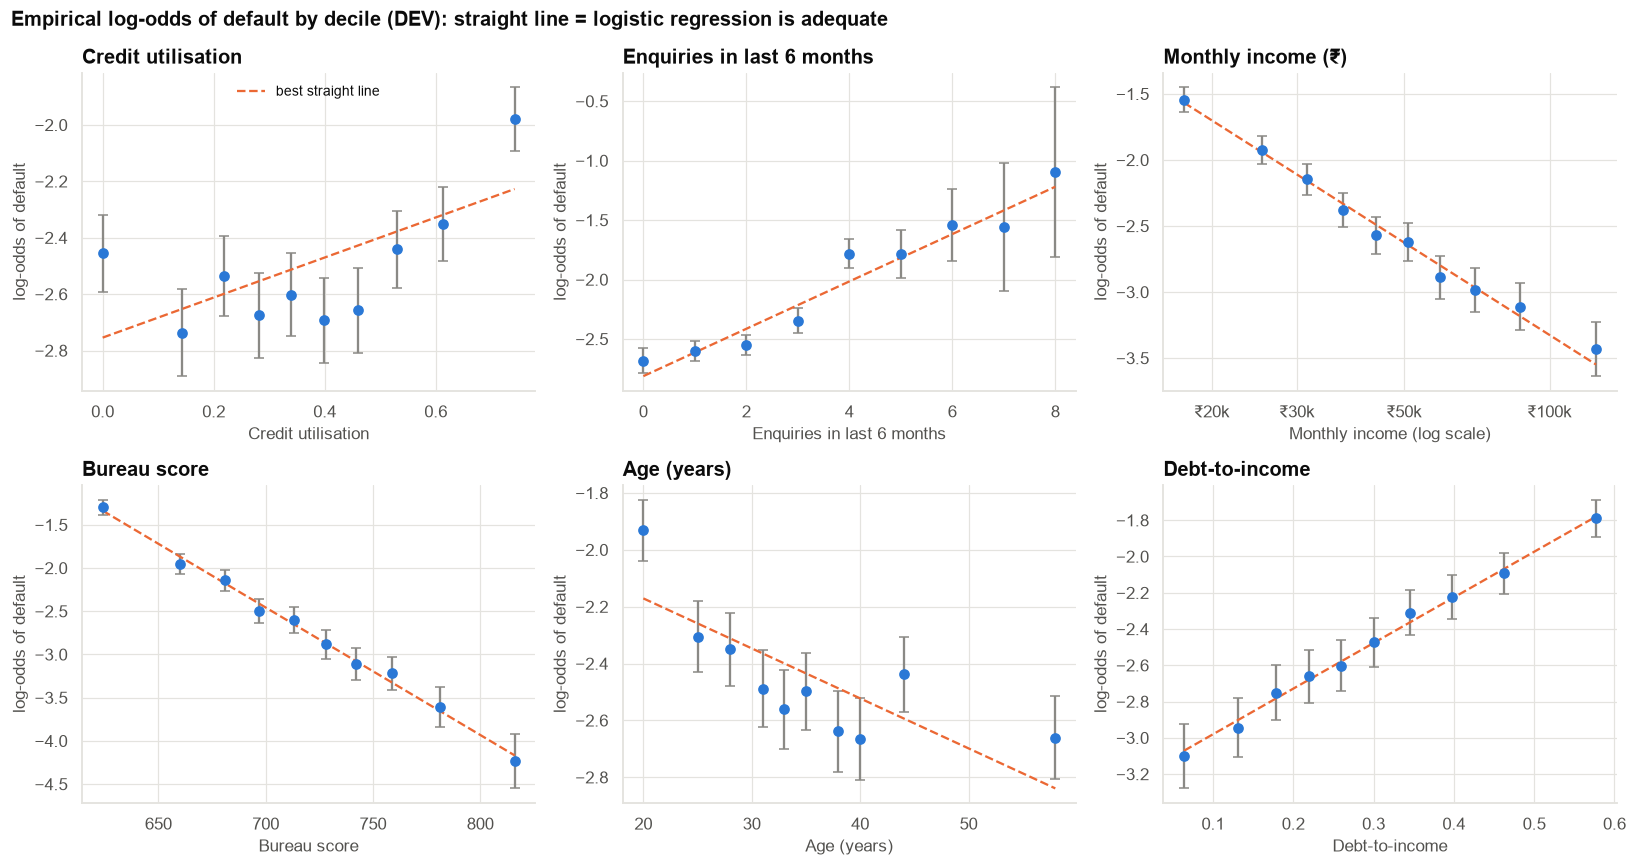

In [8]:
def binned_logodds(d, col, q=10):
    x = d[col]
    bins = pd.qcut(x.rank(method="first"), q, labels=False)
    g = d.groupby(bins).agg(x=(col, "median"), bad=(TARGET, "mean"), n=(TARGET, "size"))
    g["logodds"] = np.log(g["bad"] / (1 - g["bad"]))
    g["se"] = 1 / np.sqrt(g["n"] * g["bad"] * (1 - g["bad"]))
    return g

panels = [("utilization_f", "Credit utilisation", dev[dev["no_hit"] == 0]), ("enquiries_6m", "Enquiries in last 6 months", dev),
          ("monthly_income", "Monthly income (₹)", dev), ("bureau_score_f", "Bureau score", dev[dev["no_hit"] == 0]),
          ("age", "Age (years)", dev), ("dti", "Debt-to-income", dev)]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, label, d) in zip(axes.ravel(), panels):
    if col == "enquiries_6m":
        g = d.groupby(np.minimum(d[col], 8)).agg(x=(col, "median"), bad=(TARGET, "mean"), n=(TARGET, "size"))
        g["x"] = g.index
        g["logodds"] = np.log(g["bad"] / (1 - g["bad"]))
        g["se"] = 1 / np.sqrt(g["n"] * g["bad"] * (1 - g["bad"]))
    else:
        g = binned_logodds(d, col)
    ax.errorbar(g["x"], g["logodds"], yerr=1.96 * g["se"], fmt="o", color=PRIMARY, ecolor=INK_MUTED, capsize=3)
    xfit = np.log(g["x"]) if col == "monthly_income" else g["x"]          # income: straight line in log(income)
    lin = np.polyfit(xfit, g["logodds"], 1, w=1 / g["se"])
    xs = np.linspace(g["x"].min(), g["x"].max(), 50)
    ax.plot(xs, np.polyval(lin, np.log(xs) if col == "monthly_income" else xs), color=HIGHLIGHT, ls="--", lw=1.5,
            label="best straight line")
    ax.set(title=label, xlabel=label, ylabel="log-odds of default")
    if col == "monthly_income":
        ax.set_xscale("log")
        ax.set_xticks([20_000, 30_000, 50_000, 100_000], ["₹20k", "₹30k", "₹50k", "₹100k"])
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
        ax.set_xlabel("Monthly income (log scale)")
axes[0, 0].legend(loc="upper center", fontsize=9)
fig.suptitle("Empirical log-odds of default by decile (DEV): straight line = logistic regression is adequate",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig01_binned_logodds", PATHS["figures"])
plt.show()

**Observation.**
- **Utilisation** is clearly **U-shaped**: risk is higher at 0% (dormant or thin-file behaviour), lowest around
  30–40%, and rises steeply above ~80%. A straight line misses both ends.
- **Enquiries** look flat at 0–3 and then jump: a **threshold** effect.
- **Income** is close to linear on a **log** scale (the x-axis here), so the raw-scale linear term is misspecified.
- **Age** is roughly flat except for the youngest applicants.
- **Bureau score** and **DTI** look close to linear.

**Interpretation.** These shapes are exactly what decides "simple or complex model". Curves and thresholds can be
captured **inside** a logistic regression (splines, bins, log transforms). ML is not required to model them. What a
GLM handles less easily is *many* interactions at once.

**Caveat.** These plots are **univariate**: a curve can come from a confounder. Formal **conditional** tests follow in
Section 9.

## Section 8 — Univariate screening (with the right test for each column type)

### 8.1 Method selection

| Column type | Test | Why | Effect size |
|---|---|---|---|
| Numerical | **Mann-Whitney U** (bad vs good) | Skewed variables; robust; equivalent to univariate AUC | **AUC** (= common-language effect size), Spearman ρ |
| Ordinal | **Linear-by-linear (trend) test** + Spearman ρ | Uses the order; more powerful than χ² for monotone patterns | ρ, Cramér's V |
| Nominal | **χ² test of independence** | Unordered categories | **Cramér's V** |
| All | **Mutual information (MI)** | Detects *any* dependence, including non-monotone (U-shapes) that ρ misses | MI (nats) |

We test about 18 predictors, so some will look "significant" by chance. We control the **false discovery rate** with
Benjamini-Hochberg (Case 19 covers multiple testing in depth).

In [9]:
y_dev = dev[TARGET].to_numpy()
rows = []
num_cols = ["age", "monthly_income", "bureau_score_f", "utilization_f", "enquiries_6m", "dti",
            "years_at_employer", "num_credit_cards", "requested_limit"]
flag_cols = ["no_hit", "ever_delinquent", "recent_delinquency"]
mi_num = mutual_info_classif(dev[num_cols + flag_cols], y_dev, discrete_features=[False] * len(num_cols) + [True] * len(flag_cols),
                             n_neighbors=5, random_state=SEED)
for c, mi in zip(num_cols + flag_cols, mi_num):
    x = dev[c].to_numpy()
    mw = stats.mannwhitneyu(x[y_dev == 1], x[y_dev == 0])
    rows.append({"variable": c, "type": "numerical" if c in num_cols else "binary flag", "test": "Mann-Whitney U",
                 "p_value": mw.pvalue, "spearman_rho": stats.spearmanr(x, y_dev)[0], "pearson_r": np.corrcoef(x, y_dev)[0, 1],
                 "univariate_auc": max(roc_auc_score(y_dev, x), 1 - roc_auc_score(y_dev, x)), "cramers_v": np.nan, "mutual_info": mi})
for c in COLUMN_TYPES["ordinal"]:
    tbl = pd.crosstab(dev[c + "_score"], dev[TARGET]).to_numpy()
    tr = Table(tbl).test_ordinal_association()
    chi = stats.chi2_contingency(tbl, correction=False)
    rows.append({"variable": c, "type": "ordinal", "test": "trend (linear-by-linear)", "p_value": tr.pvalue,
                 "spearman_rho": stats.spearmanr(dev[c + "_score"], y_dev)[0], "pearson_r": np.nan, "univariate_auc": np.nan,
                 "cramers_v": np.sqrt(chi.statistic / len(dev)),
                 "mutual_info": mutual_info_classif(dev[[c + "_score"]], y_dev, discrete_features=True, random_state=SEED)[0]})
for c in COLUMN_TYPES["nominal"]:
    tbl = pd.crosstab(dev[c], dev[TARGET])
    chi = stats.chi2_contingency(tbl, correction=False)
    codes = dev[c].astype("category").cat.codes.to_numpy().reshape(-1, 1)
    rows.append({"variable": c, "type": "nominal", "test": f"chi-square (df={chi.dof})", "p_value": chi.pvalue,
                 "spearman_rho": np.nan, "pearson_r": np.nan, "univariate_auc": np.nan,
                 "cramers_v": np.sqrt(chi.statistic / (len(dev) * (min(tbl.shape) - 1))),
                 "mutual_info": mutual_info_classif(codes, y_dev, discrete_features=True, random_state=SEED)[0]})
screening = pd.DataFrame(rows).set_index("variable")
screening["q_value_BH"] = multipletests(screening["p_value"], method="fdr_bh")[1]
screening["signal?"] = np.where(screening["q_value_BH"] < 0.05, "yes", "no")
screening = screening.sort_values("mutual_info", ascending=False)
save_table(screening, "univariate_screening", PATHS["tables"])
screening

,type,test,p_value,spearman_rho,pearson_r,univariate_auc,cramers_v,mutual_info,q_value_BH,signal?
variable,,,,,,,,,,
bureau_score_f,numerical,Mann-Whitney U,0.0000,-0.1819,-0.1893,0.6928,NaN,0.0214,0.0000,yes
monthly_income,numerical,Mann-Whitney U,0.0000,-0.1473,-0.1210,0.6562,NaN,0.0115,0.0000,yes
occupation,nominal,chi-square (df=6),0.0000,NaN,NaN,NaN,0.1458,0.0102,0.0000,yes
requested_limit,numerical,Mann-Whitney U,0.0000,-0.1317,-0.1062,0.6396,NaN,0.0101,0.0000,yes
num_credit_cards,numerical,Mann-Whitney U,0.0000,-0.1323,-0.1253,0.6320,NaN,0.0100,0.0000,yes
dti,numerical,Mann-Whitney U,0.0000,0.1024,0.1084,0.6085,NaN,0.0062,0.0000,yes
utilization_f,numerical,Mann-Whitney U,0.0000,0.0382,0.0435,0.5405,NaN,0.0045,0.0000,yes
enquiries_6m,numerical,Mann-Whitney U,0.0000,0.0691,0.0817,0.5713,NaN,0.0031,0.0000,yes
years_at_employer,numerical,Mann-Whitney U,0.0000,-0.0326,-0.0261,0.5345,NaN,0.0023,0.0000,yes


**Reading the screening table.**

- Most variables carry signal after FDR control. Bureau score, utilisation, enquiries, DTI, delinquency flags,
  income, occupation and channel are the strongest.
- **`marital_status`** shows no evidence of association (q ≫ 0.05). It is a candidate to drop.
- **`city_tier` *is* associated on its own.** Hold that thought. Section 9 asks whether it survives once income is
  in the model.
- **Utilisation has a tiny Pearson correlation (≈ 0.05) but one of the highest mutual informations.** This is the
  single most important lesson about correlation in model building, shown next.

### Figure 2 — Correlation vs mutual information

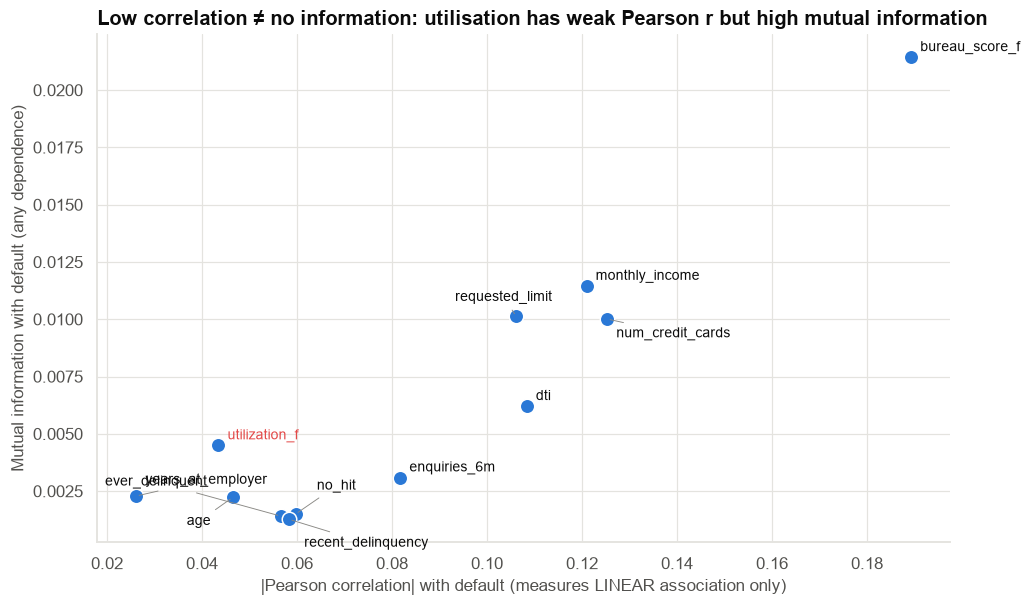

In [10]:
s = screening[screening["type"].isin(["numerical", "binary flag"])]
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(s["pearson_r"].abs(), s["mutual_info"], s=90, color=PRIMARY, edgecolor="white", zorder=3)
offsets = {"no_hit": (14, 16), "ever_delinquent": (-115, 20), "recent_delinquency": (10, -18), "age": (-30, -18),
           "years_at_employer": (6, 8), "requested_limit": (-40, 10), "num_credit_cards": (6, -12)}
for v, r in s.iterrows():
    ax.annotate(v, (abs(r["pearson_r"]), r["mutual_info"]), xytext=offsets.get(v, (6, 4)), textcoords="offset points",
                fontsize=9, color=COLORS["red"] if v == "utilization_f" else INK,
                arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=0.6) if v in offsets else None)
ax.set(title="Low correlation ≠ no information: utilisation has weak Pearson r but high mutual information",
       xlabel="|Pearson correlation| with default (measures LINEAR association only)",
       ylabel="Mutual information with default (any dependence)")
save_fig(fig, "fig02_correlation_vs_mi", PATHS["figures"])
plt.show()

**Observation.** Utilisation sits at the left (|r| ≈ 0.05) but high on mutual information.

**Interpretation.** Pearson's r measures only a **straight-line** association. A U-shaped relationship has high risk at
both ends, so the up-slope and down-slope partly cancel and r comes out small. Mutual information (and the binned
plot) see the dependence.

**Business implication.** A naive "drop features with |r| < 0.1" rule would have **thrown away one of the best
predictors**. This is also exactly where people conclude "the relationship is non-linear, so we need ML". As
Section 9 shows, a spline in a logistic regression captures it just as well.

> **What correlation can and cannot tell you in model building**
>
> | Situation | What it means | What to do |
> |---|---|---|
> | High \|r\| with target | Strong linear signal | A linear term will capture most of it |
> | Low \|r\|, high MI or curved binned plot | Non-linear signal (U-shape, threshold) | Spline / bins / transform in GLM; or tree model |
> | Low \|r\|, low MI, flat plot, conditional LRT ns | Likely no signal | Drop (unless business-mandated) |
> | High \|r\| between two **predictors** (> ~0.8) | Redundancy / multicollinearity | GLM: drop or combine, check VIF; GBM: prediction fine, importances split |
> | Strong univariate r, but vanishes when controlling for others | Proxy / confounded | Drop from explanatory model; may still help prediction marginally |
> | Single feature AUC > ~0.9 | Too good to be true | **Suspect leakage** before celebrating |

## Section 9 — Conditional tests inside a statistical model

Univariate screening asks "is X related to default **on its own**?". Model building needs "does X add information
**given everything else**?" and "is X's effect **linear**?". Likelihood-ratio tests (LRT) between **nested** logistic
regressions answer both:

  LR = 2 × (log-likelihood of bigger model − log-likelihood of smaller model) ~ χ²(df = extra parameters)

### 9.1 The baseline linear model and the "drop-one" tests

In [11]:
BASE_NUM = ["age", "log_income", "bureau_score_f", "no_hit", "utilization_f", "enquiries_6m", "ever_delinquent",
            "recent_delinquency", "dti", "years_at_employer", "num_credit_cards", "requested_limit",
            "education_score", "city_tier_score", "income_verification_score"]
NOMINAL = ["occupation", "residence_type", "acquisition_channel", "state", "marital_status"]
REFERENCE = {"occupation": "Salaried-Private", "residence_type": "Owned", "acquisition_channel": "Branch",
             "state": "Maharashtra", "marital_status": "Married"}

def design(d, num=BASE_NUM, nominal=NOMINAL, splines=None, extra=None, ordinal_as_cat=(), spline_knots=None):
    # Build a statsmodels-ready design matrix: numeric terms, one-hot nominal terms (fixed reference levels),
    # optional spline bases (knots fixed from DEV quantiles) and extra engineered columns.
    parts = [d[[c for c in num if c not in (splines or [])]].astype(float)]
    for c in list(nominal) + list(ordinal_as_cat):
        levels = sorted(dev[c].unique()) if c in nominal else ORD_LEVELS[c]
        ref = REFERENCE.get(c, levels[0])
        parts.append(pd.DataFrame({f"{c}={lv}": (d[c] == lv).astype(float) for lv in levels if lv != ref}, index=d.index))
    for c in splines or []:
        st = spline_knots[c]
        basis = st.transform(d[[c]])
        parts.append(pd.DataFrame(basis, index=d.index, columns=[f"{c}_s{i}" for i in range(basis.shape[1])]))
    if extra is not None:
        parts.append(extra.loc[d.index])
    X = pd.concat(parts, axis=1)
    if ordinal_as_cat:
        X = X.drop(columns=[c + "_score" for c in ordinal_as_cat if c + "_score" in X.columns])
    return sm.add_constant(X, has_constant="add")

def fit_logit(X, y):
    # Newton first; if it has not converged (can happen with flexible spline bases), continue with BFGS from there.
    res = sm.Logit(y, X).fit(disp=0, maxiter=100, method="newton", warn_convergence=False)
    if not res.mle_retvals.get("converged", True):
        res = sm.Logit(y, X).fit(disp=0, maxiter=5000, method="bfgs", start_params=res.params, warn_convergence=False)
    assert res.mle_retvals.get("converged", True), "logistic fit did not converge"
    return res

def lrt(small, big):
    stat = 2 * (big.llf - small.llf)
    df_ = int(big.df_model - small.df_model)
    return stat, df_, stats.chi2.sf(stat, df_)

X_base = design(dev)
m_base = fit_logit(X_base, dev[TARGET])
print(f"Baseline linear logistic: {int(m_base.df_model)} parameters, log-likelihood {m_base.llf:,.1f}, AIC {m_base.aic:,.1f}")

drop_rows = []
for v in BASE_NUM + NOMINAL:
    if v in NOMINAL:
        Xs = design(dev, nominal=[n for n in NOMINAL if n != v])
    else:
        Xs = design(dev, num=[n for n in BASE_NUM if n != v])
    stat, df_, p = lrt(fit_logit(Xs, dev[TARGET]), m_base)
    drop_rows.append({"variable": v, "LR_stat": stat, "df": df_, "p_value": p})
drop_tests = pd.DataFrame(drop_rows).set_index("variable")
drop_tests["p_holm"] = multipletests(drop_tests["p_value"], method="holm")[1]
SCREEN_NAME = {"log_income": "monthly_income", "education_score": "education", "city_tier_score": "city_tier",
               "income_verification_score": "income_verification"}
drop_tests["q_value_BH"] = [screening["q_value_BH"].get(SCREEN_NAME.get(v, v), np.nan) for v in drop_tests.index]
drop_tests["univariate_signal"] = np.where(drop_tests["q_value_BH"] < 0.05, "yes", np.where(drop_tests["q_value_BH"].isna(), "-", "no"))
drop_tests["conditional_signal"] = np.where(drop_tests["p_holm"] < 0.05, "yes", "no")
save_table(drop_tests, "conditional_drop_tests", PATHS["tables"])
drop_tests.sort_values("LR_stat", ascending=False)

Baseline linear logistic: 41 parameters, log-likelihood -7,165.8, AIC 14,415.6


,LR_stat,df,p_value,p_holm,q_value_BH,univariate_signal,conditional_signal
variable,,,,,,,
bureau_score_f,637.2951,1,0.0000,0.0000,0.0000,yes,yes
occupation,356.3313,6,0.0000,0.0000,0.0000,yes,yes
dti,128.1959,1,0.0000,0.0000,0.0000,yes,yes
enquiries_6m,109.9000,1,0.0000,0.0000,0.0000,yes,yes
no_hit,100.6480,1,0.0000,0.0000,0.0000,yes,yes
acquisition_channel,65.8677,4,0.0000,0.0000,0.0000,yes,yes
income_verification_score,56.9701,1,0.0000,0.0000,0.0000,yes,yes
log_income,47.4981,1,0.0000,0.0000,0.0000,yes,yes
recent_delinquency,38.9194,1,0.0000,0.0000,0.0000,yes,yes


**Reading the conditional tests.**

- **`city_tier`: significant on its own (Section 8) but not given the other variables.** Metro customers earn more,
  and income is in the model. City tier was a **proxy** for income. For explanation, drop it. For prediction it adds
  nothing either.
- **`marital_status`: no signal either way.** Drop.
- **`requested_limit`: no conditional signal.** It is largely a function of income (see VIF below). Drop.
- **`num_credit_cards`, `years_at_employer` and `ever_delinquent`** are significant on their own but not once score,
  income and *recent* delinquency are in the model. They are largely redundant. We keep them in M2 (harmless, and
  credit officers expect them), but they add nothing.
- **`state`** (12 levels, 11 parameters) survives the Holm adjustment as a block. **`residence_type`** is borderline
  (Holm p ≈ 0.06): too weak to insist on, too plausible to drop. We keep it.

> **If a variable is significant univariately but not conditionally**, it is usually a proxy for something already in
> the model. **If it is non-significant univariately but significant conditionally**, it is a *suppressor* (Case 08):
> keep it, and understand why.

### 9.2 Multicollinearity: VIF

,VIF
log_income,3.57
requested_limit,2.81
num_credit_cards,2.18
bureau_score_f,1.31
ever_delinquent,1.28
recent_delinquency,1.22
no_hit,1.11
dti,1.11
city_tier_score,1.06
education_score,1.03


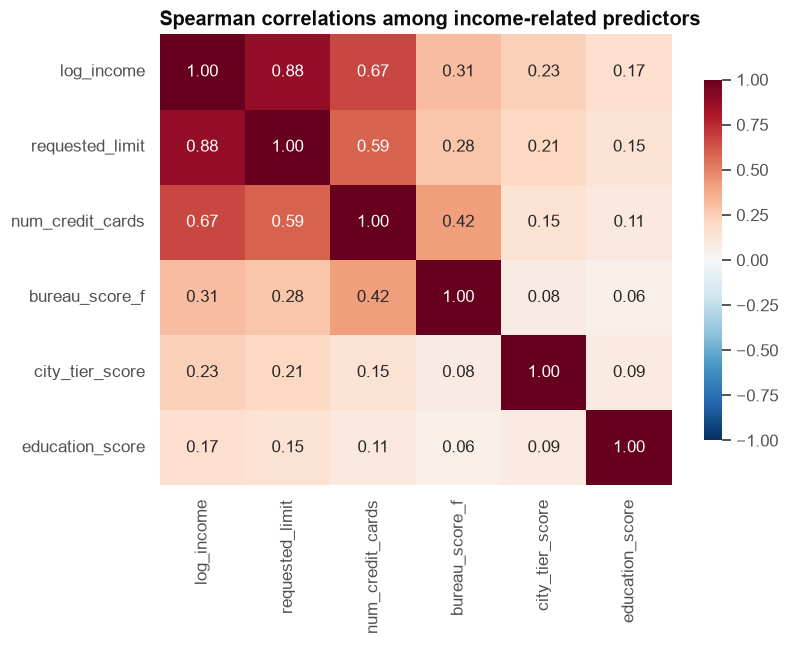

In [12]:
vif_cols = [c for c in BASE_NUM]
Xv = sm.add_constant(dev[vif_cols].astype(float))
vif = pd.Series({c: variance_inflation_factor(Xv.values, i) for i, c in enumerate(Xv.columns) if c != "const"}, name="VIF")
corr = dev[["log_income", "requested_limit", "num_credit_cards", "bureau_score_f", "city_tier_score", "education_score"]].corr(method="spearman")
save_table(vif.to_frame(), "vif", PATHS["tables"])
display(vif.sort_values(ascending=False).to_frame().style.format("{:.2f}").background_gradient(cmap="Oranges", vmin=1, vmax=10))
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlations among income-related predictors")
fig.tight_layout()
save_fig(fig, "fig03_predictor_correlations", PATHS["figures"])
plt.show()

**VIF** (variance inflation factor) measures how much a coefficient's variance is inflated because the predictor is
predictable from the others. Rules of thumb: < 5 fine, 5–10 investigate, > 10 serious. Income and requested limit are
strongly correlated (Spearman ρ ≈ 0.88), and number of cards correlates with both (≈ 0.6–0.7). Their VIFs are the
highest in the model, but still **below 5 (max ≈ 3.6)**. Pairwise correlation alone overstates the problem here,
because each variable also carries independent variation. **Multicollinearity is present but not severe.**

**What multicollinearity does and does not affect.**
- It **does not** hurt prediction much: correlated predictors share the signal.
- It **does** make individual coefficients unstable and hard to interpret. A scorecard's reason codes ("declined due
  to high requested limit") would flip-flop between correlated variables.
- Decision for M2: requested limit adds no conditional information (9.1) and is mostly a restatement of income, so
  **drop it**. For a GBM we would leave it in and accept split importances.
- **If VIFs had been > 10** (e.g., two near-duplicate income fields), we would *have* to drop or combine variables
  before interpreting any GLM coefficient.

### 9.3 Is each numeric effect linear? LRT: linear term vs spline

In [13]:
SPLINE_CANDIDATES = ["age", "log_income", "bureau_score_f", "utilization_f", "enquiries_6m", "dti", "years_at_employer", "num_credit_cards"]
def make_spline(c):
    # Quantile knots follow the data, but collapse on low-cardinality counts (many tied values) -> use evenly spaced knots there.
    return SplineTransformer(n_knots=5, degree=3, include_bias=False, knots="quantile" if dev[c].nunique() > 20 else "uniform")

knots = {c: make_spline(c).fit(dev[[c]]) for c in SPLINE_CANDIDATES}

nl_rows = []
for c in SPLINE_CANDIDATES:
    big = fit_logit(design(dev, splines=[c], spline_knots=knots), dev[TARGET])
    stat, df_, p = lrt(m_base, big)
    nl_rows.append({"variable": c, "LR_stat": stat, "df": df_, "p_value": p, "AIC_linear": m_base.aic, "AIC_spline": big.aic})
nonlin = pd.DataFrame(nl_rows).set_index("variable")
nonlin["p_holm"] = multipletests(nonlin["p_value"], method="holm")[1]
nonlin["AIC_gain"] = nonlin["AIC_linear"] - nonlin["AIC_spline"]
nonlin["decision"] = np.where(nonlin["p_holm"] < 0.05, "use spline (non-linear)", "keep linear")
# Raw income vs log income: which scale is right?
m_raw_inc = fit_logit(design(dev, num=[c if c != "log_income" else "monthly_income" for c in BASE_NUM]), dev[TARGET])
print(f"AIC with log(income): {m_base.aic:,.1f}   AIC with raw income: {m_raw_inc.aic:,.1f}  (lower is better)")
save_table(nonlin, "nonlinearity_tests", PATHS["tables"])
nonlin.sort_values("LR_stat", ascending=False)

AIC with log(income): 14,415.6   AIC with raw income: 14,440.5  (lower is better)


,LR_stat,df,p_value,AIC_linear,AIC_spline,p_holm,AIC_gain,decision
variable,,,,,,,,
utilization_f,59.4395,5,0.0000,"14,415.5952","14,366.1557",0.0000,49.4395,use spline (non-linear)
enquiries_6m,28.9310,5,0.0000,"14,415.5952","14,396.6641",0.0002,18.9310,use spline (non-linear)
age,21.9170,5,0.0005,"14,415.5952","14,403.6782",0.0033,11.9170,use spline (non-linear)
bureau_score_f,7.5316,5,0.1840,"14,415.5952","14,418.0636",0.9201,-2.4684,keep linear
log_income,6.9680,5,0.2230,"14,415.5952","14,418.6272",0.9201,-3.0320,keep linear
dti,5.1823,5,0.3940,"14,415.5952","14,420.4129",1.0000,-4.8177,keep linear
years_at_employer,4.2646,5,0.5120,"14,415.5952","14,421.3306",1.0000,-5.7354,keep linear
num_credit_cards,1.2349,5,0.9415,"14,415.5952","14,424.3603",1.0000,-8.7651,keep linear


**Reading the non-linearity tests.** The spline LRT compares a straight-line effect (1 parameter) with a smooth curve
(several parameters). A significant result (after Holm adjustment) means **the straight line is demonstrably wrong**.

- **Utilisation, enquiries and age** reject linearity strongly, matching the U-shape, threshold and young-age effects
  in Figure 1.
- **Bureau score, log-income and DTI** are adequately linear. Log income fits better than raw income (lower AIC),
  confirming the transformation.
- AIC gains tell the same story in model-fit terms.

> **If the non-linearity test is significant** → add a spline/bins for that variable in the GLM (it stays a scorecard).
> **If it is not** → keep the linear term; extra flexibility only adds variance.
> **If many variables are non-linear *and* interact in complex ways** → that is when tree-based ML starts to pull ahead.

### 9.4 Ordinal variables: linear trend or separate categories?

In [14]:
ord_rows = []
for c in ORD_LEVELS:
    big = fit_logit(design(dev, ordinal_as_cat=[c]), dev[TARGET])
    stat, df_, p = lrt(m_base, big)
    ord_rows.append({"variable": c, "levels": len(ORD_LEVELS[c]), "LR_stat (categorical vs trend)": stat, "df": df_, "p_value": p,
                     "decision": "dummies (non-linear across levels)" if p < 0.05 else "single ordinal score (linear trend adequate)"})
ordinal_tests = pd.DataFrame(ord_rows).set_index("variable")
save_table(ordinal_tests, "ordinal_coding_tests", PATHS["tables"])
ordinal_tests

,levels,LR_stat (categorical vs trend),df,p_value,decision
variable,,,,,
education,4,0.2932,2,0.8636,single ordinal score (linear trend adequate)
city_tier,4,0.8904,2,0.6407,single ordinal score (linear trend adequate)
income_verification,3,0.7552,1,0.3848,single ordinal score (linear trend adequate)


For each ordinal variable the trend model (one parameter: "each step up the scale changes the log-odds by β") is nested
in the categorical model (a separate parameter per level). If the LRT is not significant, the **trend coding is
adequate** and saves degrees of freedom. This also lets the scorecard respect the business logic that more
verification means lower risk.

### 9.5 Interactions: a short, pre-specified list

In [15]:
def interaction_cols(d):
    return pd.DataFrame({
        "dti_x_self_employed": d["dti"] * d["self_employed"],
        "util_x_score": (d["utilization_f"] - 0.35) * (d["bureau_score_f"] - 720) / 100,
        "enquiries_x_dti": d["enquiries_6m"] * d["dti"],
        "no_hit_x_age": d["no_hit"] * (d["age"] - 35),
        "income_x_self_employed": (d["log_income"] - np.log(45_000)) * d["self_employed"],
    }, index=d.index)

INT_CANDIDATES = {"dti × self-employed": ["dti_x_self_employed"], "utilisation × bureau score": ["util_x_score"],
                  "enquiries × DTI": ["enquiries_x_dti"], "no-hit × age": ["no_hit_x_age"],
                  "log income × self-employed": ["income_x_self_employed"]}
ints = interaction_cols(dev)
# (no separate self_employed main effect: it is an exact sum of three occupation dummies already in the model)
small_int = fit_logit(design(dev), dev[TARGET])
int_rows = []
for name, cols in INT_CANDIDATES.items():
    big = fit_logit(design(dev, extra=ints[cols]), dev[TARGET])
    stat, df_, p = lrt(small_int, big)
    int_rows.append({"interaction": name, "LR_stat": stat, "df": df_, "p_value": p, "coef": big.params[cols[0]]})
inter = pd.DataFrame(int_rows).set_index("interaction")
inter["p_holm"] = multipletests(inter["p_value"], method="holm")[1]
inter["decision"] = np.where(inter["p_holm"] < 0.05, "include", "exclude")
save_table(inter, "interaction_tests", PATHS["tables"])
inter

,LR_stat,df,p_value,coef,p_holm,decision
interaction,,,,,,
dti × self-employed,35.1316,1,0.0000,1.6754,0.0000,include
utilisation × bureau score,0.0323,1,0.8573,0.0357,1.0000,exclude
enquiries × DTI,5.1816,1,0.0228,0.2143,0.0913,exclude
no-hit × age,1.7061,1,0.1915,0.0096,0.5745,exclude
log income × self-employed,0.2295,1,0.6319,-0.0386,1.0000,exclude


**Why a short, pre-specified list?** With 20 predictors there are 190 possible pairwise interactions. Testing all of
them guarantees false positives, and a model built on them would not generalise. We test **five
business-motivated hypotheses** (e.g., "debt burden hurts self-employed borrowers more, because their income is
volatile") and adjust for multiplicity.

- **DTI × self-employed** is strongly significant. Debt burden is more dangerous for self-employed and gig workers.
- The others are weak or absent after adjustment (the utilisation × score interaction is small in truth; see
  `generate_data.py`).

> **If one or two interactions are significant** → add them to the GLM.
> **If you suspect many, higher-order interactions** (e.g., combinations of 3–4 variables) → a GLM becomes unwieldy,
> which is a genuine argument for tree ensembles. The scenario lab (Section 15) shows that world.

## Section 10 — Building the model ladder

The specification of **M2** comes entirely from the tests above:

| Decision | Evidence | M2 specification |
|---|---|---|
| Drop leakage | Section 5.2 | `collections_contact_flag` removed (all models) |
| Drop proxies / noise | Section 9.1 | drop `city_tier`, `marital_status`, `requested_limit` |
| Splines | Section 9.3 (Holm p < 0.05) | splines for the variables that failed linearity |
| Ordinal coding | Section 9.4 | trend scores where adequate |
| Interactions | Section 9.5 | significant interactions only |
| Income scale | AIC | log income |

In [16]:
SPLINE_VARS = list(nonlin.index[nonlin["p_holm"] < 0.05])
INTERACTIONS = [c for name, cols in INT_CANDIDATES.items() if inter.loc[name, "p_holm"] < 0.05 for c in cols]
ORD_AS_CAT = list(ordinal_tests.index[ordinal_tests["p_value"] < 0.05])
DROP = ["city_tier_score", "requested_limit"] if drop_tests.loc["city_tier_score", "p_holm"] >= 0.05 else ["requested_limit"]
M2_NUM = [c for c in BASE_NUM if c not in DROP]
M2_NOMINAL = [c for c in NOMINAL if not (c == "marital_status" and drop_tests.loc["marital_status", "p_holm"] >= 0.05)]
print("Splines for       :", SPLINE_VARS)
print("Interactions      :", INTERACTIONS)
print("Ordinal as dummies:", ORD_AS_CAT or "none (trend coding adequate)")
print("Dropped           :", DROP + [c for c in NOMINAL if c not in M2_NOMINAL])

CURRENT_SCORECARD = ["bureau_score_f", "no_hit", "monthly_income", "dti", "enquiries_6m"]   # + occupation, all linear

Splines for       : ['age', 'utilization_f', 'enquiries_6m']
Interactions      : ['dti_x_self_employed']
Ordinal as dummies: none (trend coding adequate)
Dropped           : ['city_tier_score', 'requested_limit', 'marital_status']


In [17]:
# sklearn pipelines for the four models (fitted inside each CV fold, so nothing leaks between folds)
from sklearn.preprocessing import FunctionTransformer

def add_interactions(X):
    # Stateless (no fitting), so it is safe inside cross-validation.
    return pd.concat([X, interaction_cols(X)], axis=1)

def make_m0():
    ct = ColumnTransformer([("num", StandardScaler(), CURRENT_SCORECARD),
                            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), ["occupation"])])
    return Pipeline([("ct", ct), ("lr", LogisticRegression(max_iter=3000))])

def make_m1():
    ct = ColumnTransformer([("num", StandardScaler(), BASE_NUM),
                            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), NOMINAL)])
    return Pipeline([("ct", ct), ("lr", LogisticRegression(max_iter=3000))])

def make_m2():
    lin = [c for c in M2_NUM if c not in SPLINE_VARS and c.replace("_score", "") not in ORD_AS_CAT] + INTERACTIONS
    ct = ColumnTransformer([(f"spl_{c}", make_spline(c), [c]) for c in SPLINE_VARS] +
                           [("num", StandardScaler(), lin),
                            ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), M2_NOMINAL + ORD_AS_CAT)])
    return Pipeline([("eng", FunctionTransformer(add_interactions)), ("ct", ct), ("lr", LogisticRegression(max_iter=5000))])

GBM_NUM = ["age", "monthly_income", "bureau_score", "credit_utilization", "enquiries_6m", "months_since_delinquency", "dti",
           "years_at_employer", "num_credit_cards", "requested_limit", "education_score", "city_tier_score", "income_verification_score"]

def make_m3(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=100, l2=1.0):
    # GBM handles missing values natively, so it gets the RAW columns (incl. NaN), and nominal variables as categories.
    ct = ColumnTransformer([("num", "passthrough", GBM_NUM),
                            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), NOMINAL)])
    gbm = HistGradientBoostingClassifier(learning_rate=learning_rate, max_iter=1500, max_leaf_nodes=max_leaf_nodes,
                                         min_samples_leaf=min_samples_leaf, l2_regularization=l2, early_stopping=True,
                                         validation_fraction=0.15, n_iter_no_change=40,
                                         categorical_features=[False] * len(GBM_NUM) + [True] * len(NOMINAL), random_state=SEED)
    return Pipeline([("ct", ct), ("gbm", gbm)])

### 10.1 Tuning the GBM fairly

The ML model deserves a fair chance, so we tune its key hyperparameters by 3-fold CV on DEV. **Tuning uses DEV only.**
Choosing hyperparameters on the test set would bias the comparison in the ML model's favour.

In [18]:
grid = [dict(learning_rate=lr, max_leaf_nodes=ml, min_samples_leaf=msl) for lr in (0.05, 0.1) for ml in (15, 31) for msl in (50, 200)]
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
tune_rows = []
t0 = time.time()
for g in grid:
    aucs = []
    for tr, te in inner.split(dev, dev[TARGET]):
        m = make_m3(**g).fit(dev.iloc[tr], dev[TARGET].iloc[tr])
        aucs.append(roc_auc_score(dev[TARGET].iloc[te], m.predict_proba(dev.iloc[te])[:, 1]))
    tune_rows.append({**g, "cv_auc": np.mean(aucs), "cv_sd": np.std(aucs)})
tuning = pd.DataFrame(tune_rows).sort_values("cv_auc", ascending=False)
BEST_GBM = tuning.iloc[0][["learning_rate", "max_leaf_nodes", "min_samples_leaf"]].to_dict()
BEST_GBM = {"learning_rate": float(BEST_GBM["learning_rate"]), "max_leaf_nodes": int(BEST_GBM["max_leaf_nodes"]),
            "min_samples_leaf": int(BEST_GBM["min_samples_leaf"])}
save_table(tuning, "gbm_tuning", PATHS["tables"], index=False)
print(f"Tuning took {time.time() - t0:.0f}s. Best: {BEST_GBM}")
tuning

Tuning took 156s. Best: {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}


,learning_rate,max_leaf_nodes,min_samples_leaf,cv_auc,cv_sd
0,0.0500,15,50,0.7689,0.0024
1,0.0500,15,200,0.7666,0.0037
2,0.0500,31,50,0.7646,0.0008
4,0.1000,15,50,0.7644,0.0015
5,0.1000,15,200,0.7634,0.0054
3,0.0500,31,200,0.7621,0.0008
7,0.1000,31,200,0.7609,0.0026
6,0.1000,31,50,0.7577,0.0021


## Section 11 — Model comparison

### 11.1 First, reproduce the ML team's claim

In [19]:
leak_df = df_with_leak
tr_r, te_r = train_test_split(leak_df, test_size=0.2, stratify=leak_df[TARGET], random_state=SEED)
GBM_NUM_LEAK = GBM_NUM + ["collections_contact_flag"]
def make_leaky():
    ct = ColumnTransformer([("num", "passthrough", GBM_NUM_LEAK),
                            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), NOMINAL)])
    return Pipeline([("ct", ct), ("gbm", HistGradientBoostingClassifier(**BEST_GBM, max_iter=1500, early_stopping=True, random_state=SEED,
                    categorical_features=[False] * len(GBM_NUM_LEAK) + [True] * len(NOMINAL)))])
claim = {}
claim["GBM WITH leakage, random 80/20 split"] = roc_auc_score(te_r[TARGET], make_leaky().fit(tr_r, tr_r[TARGET]).predict_proba(te_r)[:, 1])
claim["GBM without leakage, random 80/20 split"] = roc_auc_score(te_r[TARGET], make_m3(**BEST_GBM).fit(tr_r, tr_r[TARGET]).predict_proba(te_r)[:, 1])
claim["Current scorecard (M0), random 80/20 split"] = roc_auc_score(te_r[TARGET], make_m0().fit(tr_r, tr_r[TARGET]).predict_proba(te_r)[:, 1])
claim = pd.Series(claim, name="test AUC")
save_table(claim.to_frame(), "ml_team_claim_reproduced", PATHS["tables"])
claim.to_frame().style.format("{:.3f}")

,test AUC
"GBM WITH leakage, random 80/20 split",0.959
"GBM without leakage, random 80/20 split",0.766
"Current scorecard (M0), random 80/20 split",0.765


The ML team's result is reproduced, and even exceeded (AUC ≈ 0.96 on our random split). It comes almost entirely
from **`collections_contact_flag`**. Without it, the GBM's advantage over the current scorecard **disappears** (≈ 0.77
vs ≈ 0.77). The claim compared a **leaky ML model** with a
**lazy baseline**. Both are common, and both are why independent validation exists.

### 11.2 Repeated cross-validation on DEV (5 folds × 3 repeats = 15 paired comparisons)

In [20]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
MODELS = {"M0 current scorecard": make_m0, "M1 full linear": make_m1, "M2 spec. GLM": make_m2,
          "M3 GBM": lambda: make_m3(**BEST_GBM)}
fold_rows = []
t0 = time.time()
for k, (tr, te) in enumerate(cv.split(dev, dev[TARGET])):
    for name, make in MODELS.items():
        m = make().fit(dev.iloc[tr], dev[TARGET].iloc[tr])
        p = m.predict_proba(dev.iloc[te])[:, 1]
        yte = dev[TARGET].iloc[te]
        fold_rows.append({"fold": k, "model": name, "auc": roc_auc_score(yte, p), "pr_auc": average_precision_score(yte, p),
                          "brier": brier_score_loss(yte, p)})
folds = pd.DataFrame(fold_rows)
save_table(folds, "cv_fold_scores", PATHS["tables"], index=False)
print(f"CV took {time.time() - t0:.0f}s")
cv_summary = folds.groupby("model")[["auc", "pr_auc", "brier"]].agg(["mean", "std"])
cv_summary

CV took 51s


auc        pr_auc         brier       
                       mean    std   mean    std   mean    std
model                                                         
M0 current scorecard 0.7642 0.0104 0.2505 0.0155 0.0675 0.0006
M1 full linear       0.7756 0.0110 0.2741 0.0180 0.0665 0.0008
M2 spec. GLM         0.7810 0.0114 0.2817 0.0163 0.0661 0.0008
M3 GBM               0.7726 0.0112 0.2627 0.0140 0.0669 0.0007

In [21]:
n_train, n_test = int(len(dev) * 0.8), int(len(dev) * 0.2)
pairs = [("M1 full linear", "M0 current scorecard"), ("M2 spec. GLM", "M1 full linear"),
         ("M2 spec. GLM", "M0 current scorecard"), ("M3 GBM", "M1 full linear"), ("M3 GBM", "M2 spec. GLM")]
cv_tests = []
for a, b in pairs:
    sa = folds[folds["model"] == a].sort_values("fold")["auc"].to_numpy()
    sb = folds[folds["model"] == b].sort_values("fold")["auc"].to_numpy()
    r = corrected_resampled_ttest(sa, sb, n_train, n_test)
    cv_tests.append({"comparison": f"{a} − {b}", **r})
cv_tests = pd.DataFrame(cv_tests).set_index("comparison")
save_table(cv_tests, "cv_corrected_ttests", PATHS["tables"])
cv_tests[["mean_diff", "ci_low", "ci_high", "t_corrected", "p_corrected", "t_naive", "p_naive"]]

,mean_diff,ci_low,ci_high,t_corrected,p_corrected,t_naive,p_naive
comparison,,,,,,,
M1 full linear − M0 current scorecard,0.0114,0.0061,0.0168,4.5919,0.0004,10.0072,0.0000
M2 spec. GLM − M1 full linear,0.0054,0.0027,0.0081,4.3242,0.0007,9.4239,0.0000
M2 spec. GLM − M0 current scorecard,0.0168,0.0109,0.0228,6.0633,0.0000,13.2141,0.0000
M3 GBM − M1 full linear,-0.0030,-0.0080,0.0020,-1.2969,0.2156,-2.8264,0.0135
M3 GBM − M2 spec. GLM,-0.0084,-0.0121,-0.0048,-4.9314,0.0002,-10.7473,0.0000


**Why the corrected test?** The 15 fold scores are **not independent**: every pair of folds shares most of its
training data. A naive paired t-test treats them as independent and is badly over-confident. Compare `p_naive` with
`p_corrected`. The **Nadeau-Bengio correction** inflates the variance by (1/k + n_test/n_train) and gives honest
p-values and CIs.

> **If the naive and corrected tests disagree, trust the corrected one.** "Significant" model improvements reported
> from naive CV t-tests are a frequent source of models that disappoint in production.

### Figure 4 — Fold-by-fold AUCs

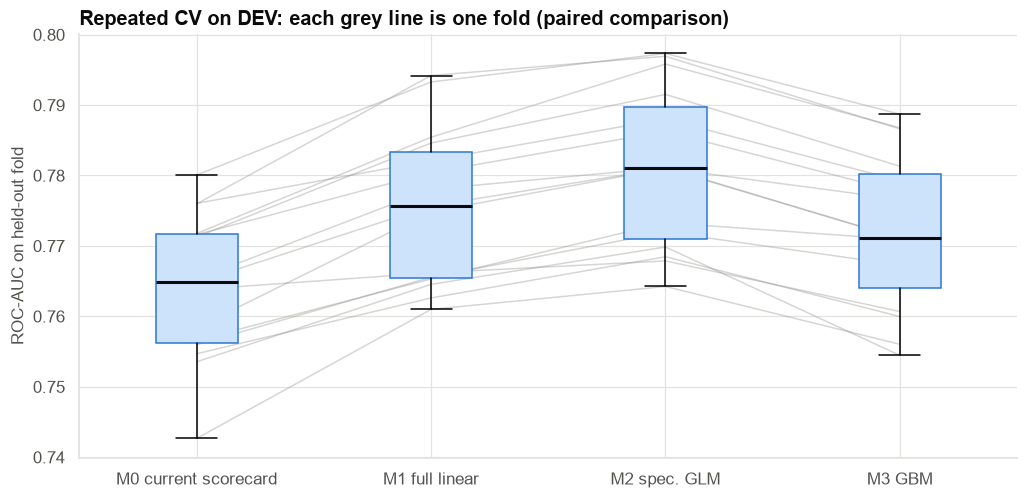

In [22]:
order = list(MODELS)
fig, ax = plt.subplots(figsize=(11, 5))
pivot = folds.pivot(index="fold", columns="model", values="auc")[order]
for _, row in pivot.iterrows():
    ax.plot(range(len(order)), row.values, color=INK_MUTED, alpha=0.35, lw=1)
ax.boxplot([pivot[c] for c in order], positions=range(len(order)), widths=0.35, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=PRIMARY), medianprops=dict(color=INK, lw=2), showfliers=False)
ax.set_xticks(range(len(order)), order)
ax.set(title="Repeated CV on DEV: each grey line is one fold (paired comparison)", ylabel="ROC-AUC on held-out fold")
save_fig(fig, "fig04_cv_auc_by_model", PATHS["figures"])
plt.show()

### 11.3 Out-of-time test (the decisive evidence)

Each model is now refitted on **all of DEV** and scored **once** on the 6 OOT months.

In [23]:
final = {name: make().fit(dev, dev[TARGET]) for name, make in MODELS.items()}
y_oot = oot[TARGET].to_numpy()
p_oot = {name: m.predict_proba(oot)[:, 1] for name, m in final.items()}
p_dev = {name: m.predict_proba(dev)[:, 1] for name, m in final.items()}

def calib_slope(y, p):
    lp = np.log(p / (1 - p))
    fit = sm.Logit(y, sm.add_constant(lp)).fit(disp=0)
    return fit.params[1], fit.params[0]

oot_rows = []
for name, p in p_oot.items():
    slope, intercept = calib_slope(y_oot, p)
    oot_rows.append({"model": name, "auc_oot": roc_auc_score(y_oot, p), "auc_dev_insample": roc_auc_score(dev[TARGET], p_dev[name]),
                     "pr_auc_oot": average_precision_score(y_oot, p), "brier_oot": brier_score_loss(y_oot, p),
                     "calibration_slope": slope, "calibration_intercept": intercept,
                     "mean_pred_oot": p.mean(), "actual_bad_rate_oot": y_oot.mean()})
oot_perf = pd.DataFrame(oot_rows).set_index("model")
oot_perf["overfit_gap"] = oot_perf["auc_dev_insample"] - oot_perf["auc_oot"]
save_table(oot_perf, "oot_performance", PATHS["tables"])
oot_perf

,auc_oot,auc_dev_insample,pr_auc_oot,brier_oot,calibration_slope,calibration_intercept,mean_pred_oot,actual_bad_rate_oot,overfit_gap
model,,,,,,,,,
M0 current scorecard,0.7707,0.7655,0.2643,0.0666,1.0446,0.0819,0.0809,0.0803,-0.0052
M1 full linear,0.7814,0.7793,0.2836,0.0657,1.0238,0.0181,0.0822,0.0803,-0.0021
M2 spec. GLM,0.7874,0.7849,0.3049,0.0649,1.0267,0.0170,0.0826,0.0803,-0.0025
M3 GBM,0.7785,0.8341,0.2780,0.0659,1.0074,-0.0118,0.0820,0.0803,0.0556


In [24]:
oot_tests = []
for a, b in pairs:
    r = delong_test(y_oot, p_oot[a], p_oot[b])
    boot = []
    idx = np.arange(len(y_oot))
    for _ in range(1000):
        s = rng.choice(idx, len(idx))
        boot.append(roc_auc_score(y_oot[s], p_oot[a][s]) - roc_auc_score(y_oot[s], p_oot[b][s]))
    oot_tests.append({"comparison": f"{a} − {b}", "auc_diff": r["diff"], "delong_ci_low": r["ci_low"], "delong_ci_high": r["ci_high"],
                      "delong_p": r["p_value"], "bootstrap_ci_low": np.quantile(boot, 0.025), "bootstrap_ci_high": np.quantile(boot, 0.975)})
oot_tests = pd.DataFrame(oot_tests).set_index("comparison")
save_table(oot_tests, "oot_delong_bootstrap", PATHS["tables"])
oot_tests

,auc_diff,delong_ci_low,delong_ci_high,delong_p,bootstrap_ci_low,bootstrap_ci_high
comparison,,,,,,
M1 full linear − M0 current scorecard,0.0107,0.0045,0.0169,0.0007,0.0043,0.0172
M2 spec. GLM − M1 full linear,0.0060,0.0019,0.0101,0.0045,0.0023,0.0099
M2 spec. GLM − M0 current scorecard,0.0167,0.0093,0.0241,0.0000,0.0094,0.0242
M3 GBM − M1 full linear,-0.0029,-0.0090,0.0032,0.3482,-0.0087,0.0029
M3 GBM − M2 spec. GLM,-0.0089,-0.0143,-0.0035,0.0012,-0.0146,-0.0036


**DeLong test.** The two AUCs are computed on the **same** OOT applicants, so they are correlated. DeLong's method
accounts for this and gives a valid SE for the difference. The **bootstrap** (resampling applicants) is an
assumption-light check and should agree.

### Figure 5 — ROC curves and calibration on OOT

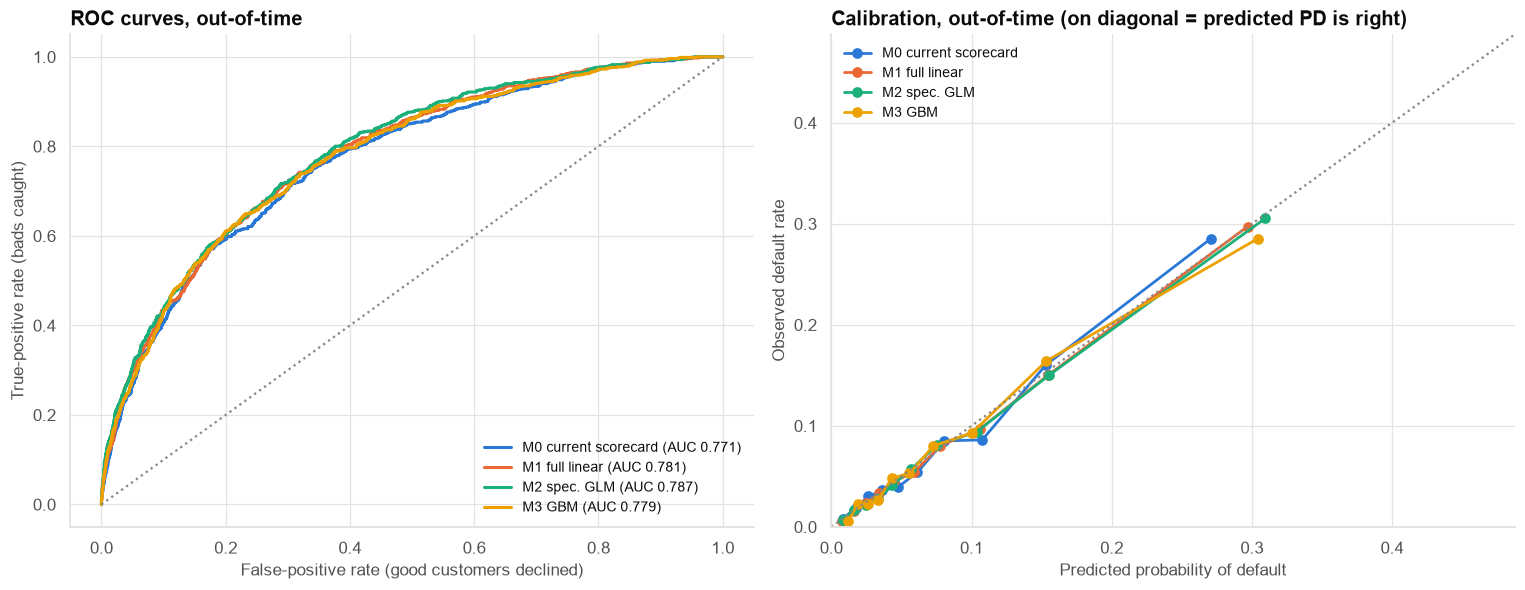

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for (name, p), color in zip(p_oot.items(), CATEGORICAL):
    fpr, tpr, _ = roc_curve(y_oot, p)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC {roc_auc_score(y_oot, p):.3f})")
    frac, mean_p = calibration_curve(y_oot, p, n_bins=10, strategy="quantile")
    axes[1].plot(mean_p, frac, marker="o", color=color, lw=1.8, label=name)
axes[0].plot([0, 1], [0, 1], color=INK_MUTED, ls=":")
axes[0].set(title="ROC curves, out-of-time", xlabel="False-positive rate (good customers declined)", ylabel="True-positive rate (bads caught)")
axes[0].legend(loc="lower right", fontsize=9)
lim = max(max(p.max() for p in p_oot.values()) * 0.6, 0.35)
axes[1].plot([0, lim], [0, lim], color=INK_MUTED, ls=":")
axes[1].set(title="Calibration, out-of-time (on diagonal = predicted PD is right)", xlabel="Predicted probability of default",
            ylabel="Observed default rate", xlim=(0, lim), ylim=(0, lim))
axes[1].legend(loc="upper left", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig05_roc_calibration_oot", PATHS["figures"])
plt.show()

**Calibration matters as much as ranking in credit.** Predicted PDs feed pricing, limits and provisioning. A
**calibration slope** near 1 means the predictions are neither over- nor under-confident. A slope below 1 means
predictions are too extreme, the usual symptom of overfitting. The mean predicted PD vs the actual OOT bad rate shows
whether the level has drifted.

### 11.4 McNemar's test at the operating point

AUC summarises all thresholds, but the bank uses **one** policy: decline the riskiest 15%. McNemar's test compares two
models' **decisions** on the same applicants. It counts only the applicants on whom they disagree.

In [26]:
def decisions(p, rate=DECLINE_RATE):
    return p >= np.quantile(p, 1 - rate)          # True = decline

def correct(p, y):
    d = decisions(p)
    return (d & (y == 1)) | (~d & (y == 0))       # decline a bad or approve a good

mc_rows = []
for a, b in pairs:
    ca, cb = correct(p_oot[a], y_oot), correct(p_oot[b], y_oot)
    tbl = pd.crosstab(ca, cb).reindex(index=[True, False], columns=[True, False], fill_value=0).to_numpy()
    res = mcnemar(tbl, exact=False, correction=True)
    mc_rows.append({"comparison": f"{a} − {b}", "only_A_correct": tbl[0, 1], "only_B_correct": tbl[1, 0],
                    "chi2": res.statistic, "p_value": res.pvalue,
                    "bads_caught_A": int((decisions(p_oot[a]) & (y_oot == 1)).sum()),
                    "bads_caught_B": int((decisions(p_oot[b]) & (y_oot == 1)).sum())})
mcn = pd.DataFrame(mc_rows).set_index("comparison")
save_table(mcn, "mcnemar_operating_point", PATHS["tables"])
mcn

,only_A_correct,only_B_correct,chi2,p_value,bads_caught_A,bads_caught_B
comparison,,,,,,
M1 full linear − M0 current scorecard,289,281,0.0860,0.7694,370,366
M2 spec. GLM − M1 full linear,191,161,2.3892,0.1222,385,370
M2 spec. GLM − M0 current scorecard,351,313,2.0617,0.1510,385,366
M3 GBM − M1 full linear,306,270,2.1267,0.1447,388,370
M3 GBM − M2 spec. GLM,263,257,0.0481,0.8264,388,385


### 11.5 Stability: population stability index (PSI) and performance over time

In [27]:
psi_rows = [{"item": f"score: {name}", "PSI": psi(p_dev[name], p_oot[name])} for name in MODELS]
for c in ["credit_utilization", "enquiries_6m", "monthly_income", "dti"]:
    psi_rows.append({"item": f"feature: {c}", "PSI": psi(dev[c].dropna(), oot[c].dropna())})
chan = pd.concat([dev["acquisition_channel"].value_counts(normalize=True), oot["acquisition_channel"].value_counts(normalize=True)], axis=1)
chan.columns = ["dev", "oot"]
psi_rows.append({"item": "feature: acquisition_channel", "PSI": float(((chan["oot"] - chan["dev"]) * np.log(chan["oot"] / chan["dev"])).sum())})
stability = pd.DataFrame(psi_rows).set_index("item")
stability["reading"] = pd.cut(stability["PSI"], [-1, 0.10, 0.25, 10], labels=["stable", "moderate shift", "major shift"])
save_table(stability, "psi_stability", PATHS["tables"])
display(stability)

oot["quarter"] = np.where(oot["application_month"] < "2024-10", "2024-Q3", "2024-Q4")
by_q = pd.DataFrame({name: [roc_auc_score(oot.loc[oot["quarter"] == q, TARGET], p[oot["quarter"].to_numpy() == q]) for q in ["2024-Q3", "2024-Q4"]]
                     for name, p in p_oot.items()}, index=["2024-Q3", "2024-Q4"])
save_table(by_q, "auc_by_quarter", PATHS["tables"])
by_q

,PSI,reading
item,,
score: M0 current scorecard,0.0011,stable
score: M1 full linear,0.0019,stable
score: M2 spec. GLM,0.0036,stable
score: M3 GBM,0.0018,stable
feature: credit_utilization,0.0269,stable
feature: enquiries_6m,0.0003,stable
feature: monthly_income,0.0020,stable
feature: dti,0.0015,stable
feature: acquisition_channel,0.0242,stable


,M0 current scorecard,M1 full linear,M2 spec. GLM,M3 GBM
2024-Q3,0.7706,0.7792,0.7855,0.7800
2024-Q4,0.7708,0.7835,0.7891,0.7770


PSI rule of thumb: < 0.10 stable, 0.10–0.25 moderate shift (monitor), > 0.25 major shift (investigate or retrain).
2024 brought slightly more aggregator-sourced customers and higher utilisation. These are the largest feature PSIs
here, but every PSI is well below 0.10, and AUCs are steady from Q3 to Q4. **All models are stable over this
window.** If one model's score PSI or OOT degradation had been much worse, that would argue against it regardless
of its DEV performance.

### 11.6 Learning curves: would more data change the answer?

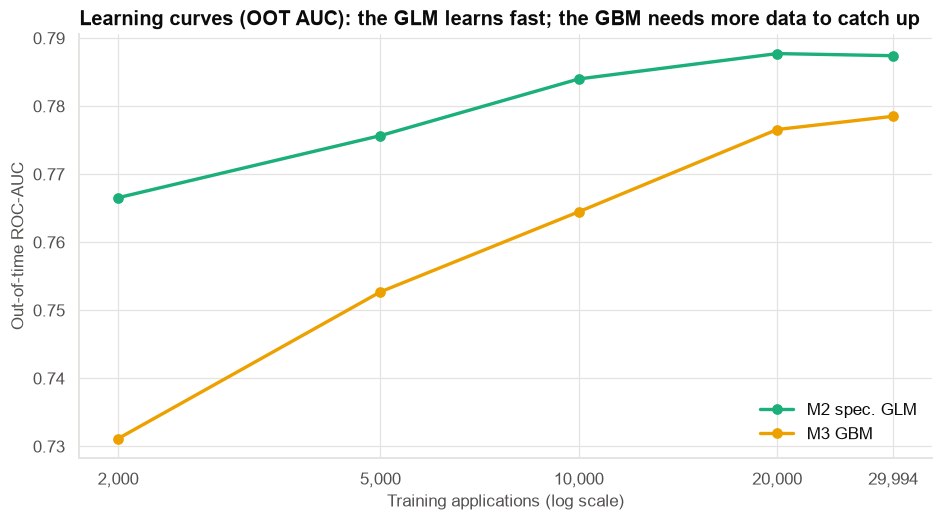

model,M2 spec. GLM,M3 GBM
n_train,,
2000,0.7665,0.7311
5000,0.7757,0.7527
10000,0.7840,0.7645
20000,0.7877,0.7766
29994,0.7874,0.7785


In [28]:
sizes = [2_000, 5_000, 10_000, 20_000, len(dev)]
lc_rows = []
for n in sizes:
    for rep in range(2 if n < len(dev) else 1):
        sub = dev.sample(n, random_state=SEED + rep) if n < len(dev) else dev
        for name in ["M2 spec. GLM", "M3 GBM"]:
            m = MODELS[name]().fit(sub, sub[TARGET])
            lc_rows.append({"n_train": n, "model": name, "auc_oot": roc_auc_score(y_oot, m.predict_proba(oot)[:, 1])})
lc = pd.DataFrame(lc_rows).groupby(["n_train", "model"])["auc_oot"].mean().unstack()
save_table(lc, "learning_curves", PATHS["tables"])

fig, ax = plt.subplots(figsize=(10, 5))
for name, color in [("M2 spec. GLM", COLORS["aqua"]), ("M3 GBM", COLORS["yellow"])]:
    ax.plot(lc.index, lc[name], marker="o", lw=2.2, color=color, label=name)
ax.set_xscale("log")
ax.set_xticks(sizes, [f"{s:,}" for s in sizes])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set(title="Learning curves (OOT AUC): the GLM learns fast; the GBM needs more data to catch up",
       xlabel="Training applications (log scale)", ylabel="Out-of-time ROC-AUC")
ax.legend(loc="lower right")
save_fig(fig, "fig06_learning_curves", PATHS["figures"])
plt.show()
lc

**Reading the learning curve.** A flexible model needs more data to estimate its many implicit parameters. If the GBM
curve is **still rising steeply** at the full sample while the GLM has flattened, more data (e.g., two more years, or
pooling products) could tip the balance towards ML. **Re-run this comparison when the data grows.** If both curves
have flattened, more data will not help either model much.

## Section 12 — Is it worth it in money?

Policy: decline the riskiest 15% of applicants; approve the rest. Value = profit from approved good customers − losses
on approved bads. We compute it on OOT for each model, bootstrap the **difference** between models, and scale to
200,000 applications a year.

In [29]:
def policy_value(p, y):
    approve = ~decisions(p)
    return (PROFIT_PER_GOOD * ((y == 0) & approve).sum() - LOSS_PER_BAD * ((y == 1) & approve).sum()) / len(y)  # ₹ per application

scale = APPS_PER_YEAR / 1e5      # per-application ₹ -> ₹ lakh per year
val = pd.Series({name: policy_value(p, y_oot) * scale for name, p in p_oot.items()}, name="value ₹ lakh / year")
idx = np.arange(len(y_oot))
boot_vals = {name: [] for name in p_oot}
for _ in range(1000):
    s = rng.choice(idx, len(idx))
    for name, p in p_oot.items():
        boot_vals[name].append(policy_value(p[s], y_oot[s]) * scale)
boot_vals = {k: np.array(v) for k, v in boot_vals.items()}
val_rows = []
for a, b in pairs:
    d = boot_vals[a] - boot_vals[b]
    val_rows.append({"comparison": f"{a} − {b}", "value_gain_lakh_per_year": val[a] - val[b],
                     "ci_low": np.quantile(d, 0.025), "ci_high": np.quantile(d, 0.975), "P(gain > 0)": (d > 0).mean()})
value = pd.DataFrame(val_rows).set_index("comparison")
value.loc["M3 GBM − M2 spec. GLM", "net_of_ML_cost"] = value.loc["M3 GBM − M2 spec. GLM", "value_gain_lakh_per_year"] - ML_EXTRA_COST_LAKH
value.loc["M3 GBM − M2 spec. GLM", "P(gain > ML cost)"] = (boot_vals["M3 GBM"] - boot_vals["M2 spec. GLM"] > ML_EXTRA_COST_LAKH).mean()
save_table(value, "value_comparison", PATHS["tables"])
save_table(val.to_frame(), "value_by_model", PATHS["tables"])
display(val.to_frame().style.format("₹{:,.0f} lakh"))
value

,value ₹ lakh / year
M0 current scorecard,"₹2,020 lakh"
M1 full linear,"₹2,072 lakh"
M2 spec. GLM,"₹2,266 lakh"
M3 GBM,"₹2,304 lakh"


,value_gain_lakh_per_year,ci_low,ci_high,P(gain > 0),net_of_ML_cost,P(gain > ML cost)
comparison,,,,,,
M1 full linear − M0 current scorecard,51.6465,-192.7960,271.1891,0.5970,NaN,NaN
M2 spec. GLM − M1 full linear,193.6743,26.7015,349.5146,0.9890,NaN,NaN
M2 spec. GLM − M0 current scorecard,245.3208,-23.1658,454.8193,0.9650,NaN,NaN
M3 GBM − M1 full linear,232.4092,0.8783,440.1737,0.9750,NaN,NaN
M3 GBM − M2 spec. GLM,38.7349,-167.8511,232.4092,0.6440,-6.2651,0.4650


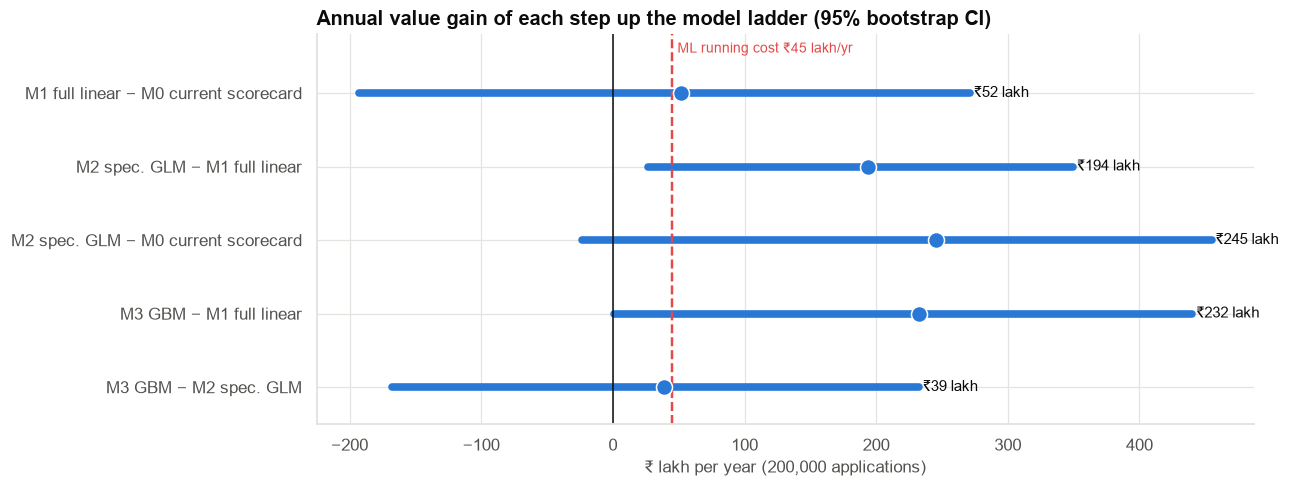

In [30]:
fig, ax = plt.subplots(figsize=(11, 4.6))
labels = list(value.index)
for i, (comp, r) in enumerate(value.iterrows()):
    ax.plot([r["ci_low"], r["ci_high"]], [i, i], color=PRIMARY, lw=5, solid_capstyle="round")
    ax.scatter(r["value_gain_lakh_per_year"], i, s=110, color=PRIMARY, edgecolor="white", zorder=3)
    ax.text(r["ci_high"] + 3, i, f"₹{r['value_gain_lakh_per_year']:,.0f} lakh", va="center", fontsize=10)
ax.axvline(0, color=INK, lw=1)
ax.axvline(ML_EXTRA_COST_LAKH, color=COLORS["red"], ls="--", lw=1.6)
ax.text(ML_EXTRA_COST_LAKH + 4, -0.55, f"ML running cost ₹{ML_EXTRA_COST_LAKH} lakh/yr", color=COLORS["red"], fontsize=9, ha="left")
ax.set_ylim(len(labels) - 0.5, -0.8)
ax.set_yticks(range(len(labels)), labels)
ax.set(title="Annual value gain of each step up the model ladder (95% bootstrap CI)", xlabel="₹ lakh per year (200,000 applications)")
save_fig(fig, "fig07_value_gain", PATHS["figures"])
plt.show()

**Reading the value results: AUC and money do not always agree.**

- **M2 vs M1** is the most reliable value gain (CI clearly above zero). The non-linear utilisation/enquiries terms
  and the self-employed DTI interaction change *who* is declined near the cut-off.
- **M1 vs M0** has a clearly significant AUC gain, but a value gain whose CI spans zero. AUC summarises ranking
  across *all* thresholds, while value depends on ranking **near the 15% cut-off**. Always compute value at the
  operating point you will actually use.
- **M3 vs M2: the GBM has a *lower* AUC but a *slightly higher* point estimate of value** (about ₹39 lakh a year).
  The CI is very wide (roughly −₹170 to +₹230 lakh), the McNemar test finds no difference in decisions, and the
  chance that the gain exceeds the ₹45 lakh running cost is a coin flip (≈ 46%). **That is not a sound basis for a
  costly, harder-to-govern model.** It is, however, a reason to keep watching the GBM as a challenger.

## Section 13 — Explainability and model risk

| Criterion | M2 specified GLM | M3 GBM |
|---|---|---|
| Reason codes for declined applicants | Directly from coefficients / points | Needs SHAP-type approximations, which must be validated |
| Monotonicity (e.g., higher score → lower risk) | Guaranteed by design | Must be imposed via constraints, otherwise can break locally |
| Validation effort (Model Risk) | Standard scorecard process | Extended: stability, explainability, bias testing |
| Monitoring | Existing scorecard monitoring | New pipeline, drift detection, retraining cadence |
| Annual running cost (incremental) | ≈ 0 (one-off ₹6 lakh upgrade) | ≈ ₹45 lakh |

These are business costs and risks. The value comparison above must clear them, with its uncertainty, before ML is
justified.

In [31]:
# What drives each model? Coefficients (as odds ratios) for M2's linear part, permutation importance for M3.
from sklearn.inspection import permutation_importance
pi = permutation_importance(final["M3 GBM"], oot, oot[TARGET], scoring="roc_auc", n_repeats=3, random_state=SEED,
                            n_jobs=1)
imp = pd.Series(pi.importances_mean, index=oot.columns).loc[GBM_NUM + NOMINAL].sort_values(ascending=False)
save_table(imp.to_frame("permutation_importance_auc_drop"), "gbm_permutation_importance", PATHS["tables"])
imp.head(12).to_frame("drop in OOT AUC when shuffled")

,drop in OOT AUC when shuffled
bureau_score,0.0987
occupation,0.0433
monthly_income,0.0153
dti,0.0135
credit_utilization,0.0080
enquiries_6m,0.0079
income_verification_score,0.0055
acquisition_channel,0.0032
age,0.0026
requested_limit,0.0022


The GBM's most important features are the same ones the statistical tests flagged (bureau score, utilisation,
enquiries, delinquency history, DTI, occupation). **The ML model found the same signal; it did not find new signal.**
That is typical when a well-specified GLM and a GBM perform similarly.

## Section 14 — Scenario lab: when *would* ML be worth it?

Our conclusion depends on the structure of *this* problem. To make the decision rules concrete, we simulate four
worlds with known truth and run the same comparison (logistic regression vs GBM, 5×2 repeated CV, corrected t-test).

| World | True structure | What a good analyst should conclude |
|---|---|---|
| **A. Linear** | Log-odds is a weighted sum of 4 features | Logistic regression; ML adds variance only |
| **B. Strongly non-linear, interacting** | Sine-shaped effect, a product interaction, a 2-way threshold rule, an absolute-value effect | ML is worth it (or a much richer GLM) |
| **C. No signal** | Target independent of features | **No model.** Fix the data or the question |
| **D. Small data, many features** | Linear in 3 of 30 features, n = 800 (~100 events) | Simple, regularised model; ML overfits |

In [32]:
lab_rng = np.random.default_rng(2024)

def make_world(kind):
    if kind == "D. Small data, many features":
        n, p = 800, 30
    else:
        n, p = 10_000, 8
    X = lab_rng.normal(size=(n, p))
    if kind == "A. Linear":
        lp = 0.8 * X[:, 0] - 0.6 * X[:, 1] + 0.5 * X[:, 2] + 0.3 * X[:, 3]
    elif kind == "B. Strongly non-linear":
        lp = 1.6 * np.sin(1.8 * X[:, 0]) + 1.4 * X[:, 1] * X[:, 2] + 1.2 * ((X[:, 3] > 0.5) & (X[:, 4] > 0)) + 0.8 * np.abs(X[:, 5])
    elif kind == "C. No signal":
        lp = np.zeros(n)
    else:
        lp = 0.9 * X[:, 0] - 0.7 * X[:, 1] + 0.5 * X[:, 2]
    y = (lab_rng.random(n) < 1 / (1 + np.exp(-(lp - 2.0)))).astype(int)
    return X, y

lab_rows = []
lab_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
for kind in ["A. Linear", "B. Strongly non-linear", "C. No signal", "D. Small data, many features"]:
    X, y = make_world(kind)
    a_lr, a_gb = [], []
    for tr, te in lab_cv.split(X, y):
        lr = LogisticRegression(max_iter=3000, C=0.5).fit(X[tr], y[tr])
        gb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=600, max_leaf_nodes=15, min_samples_leaf=30,
                                            early_stopping=True, random_state=SEED).fit(X[tr], y[tr])
        a_lr.append(roc_auc_score(y[te], lr.predict_proba(X[te])[:, 1]))
        a_gb.append(roc_auc_score(y[te], gb.predict_proba(X[te])[:, 1]))
    r = corrected_resampled_ttest(a_gb, a_lr, int(len(y) * 0.8), int(len(y) * 0.2))
    # Is the best model better than chance? Permutation test on the logistic CV AUC (shuffled labels).
    null = []
    for _ in range(30):
        ys = lab_rng.permutation(y)
        tr, te = next(StratifiedKFold(5, shuffle=True, random_state=1).split(X, ys))
        null.append(roc_auc_score(ys[te], LogisticRegression(max_iter=2000).fit(X[tr], ys[tr]).predict_proba(X[te])[:, 1]))
    best = max(np.mean(a_lr), np.mean(a_gb))
    lab_rows.append({"world": kind, "n": len(y), "events": int(y.sum()), "AUC logistic": np.mean(a_lr), "AUC GBM": np.mean(a_gb),
                     "GBM − LR": r["mean_diff"], "CI low": r["ci_low"], "CI high": r["ci_high"],
                     "p corrected": r["p_corrected"], "p naive": r["p_naive"],
                     "best AUC vs null (95th pct)": f"{best:.3f} vs {np.quantile(null, 0.95):.3f}"})
lab = pd.DataFrame(lab_rows).set_index("world")
def lab_decision(r):
    best = max(r["AUC logistic"], r["AUC GBM"])
    if best < 0.55:
        return "No usable signal → don't model; revisit data/target"
    if r["CI low"] > 0:
        return "GBM significantly better → ML worth evaluating on value"
    if r["CI high"] < 0:
        return "GBM significantly WORSE → logistic"
    return "No significant difference → prefer simpler model"
lab["decision"] = lab.apply(lab_decision, axis=1)
save_table(lab, "scenario_lab", PATHS["tables"])
lab

,n,events,AUC logistic,AUC GBM,GBM − LR,CI low,CI high,p corrected,p naive,best AUC vs null (95th pct),decision
world,,,,,,,,,,,
A. Linear,10000,1690,0.7820,0.7668,-0.0153,-0.0229,-0.0077,0.0014,0.0000,0.782 vs 0.533,GBM significantly WORSE → logistic
B. Strongly non-linear,10000,3210,0.6487,0.8193,0.1707,0.1586,0.1828,0.0000,0.0000,0.819 vs 0.521,GBM significantly better → ML worth evaluating...
C. No signal,10000,1177,0.4870,0.4904,0.0034,-0.0306,0.0374,0.8238,0.6781,0.490 vs 0.539,No usable signal → don't model; revisit data/t...
"D. Small data, many features",800,144,0.7591,0.7155,-0.0436,-0.1027,0.0154,0.1290,0.0122,0.759 vs 0.574,No significant difference → prefer simpler model


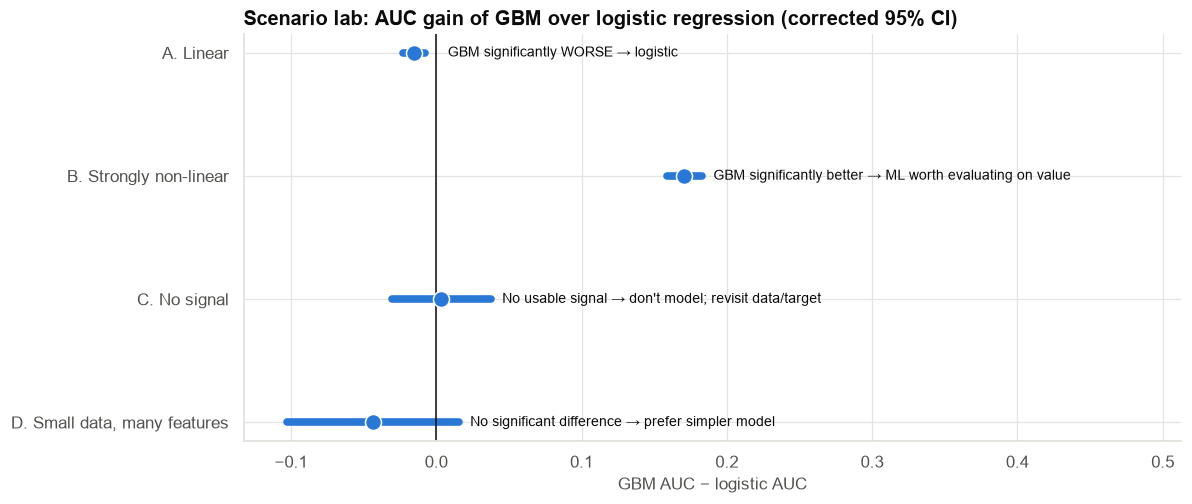

In [33]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (w, r) in enumerate(lab.iterrows()):
    ax.plot([r["CI low"], r["CI high"]], [i, i], color=PRIMARY, lw=5, solid_capstyle="round")
    ax.scatter(r["GBM − LR"], i, s=110, color=PRIMARY, edgecolor="white", zorder=3)
    ax.text(max(r["CI high"], 0) + 0.008, i, r["decision"], va="center", fontsize=9)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(len(lab)), lab.index)
ax.invert_yaxis()
ax.set_xlim(lab["CI low"].min() - 0.03, lab["CI high"].max() + 0.33)
ax.set(title="Scenario lab: AUC gain of GBM over logistic regression (corrected 95% CI)", xlabel="GBM AUC − logistic AUC")
save_fig(fig, "fig08_scenario_lab", PATHS["figures"])
plt.show()

**What the scenario lab teaches**

- **World A (linear):** GBM is not better, and is often slightly worse: it spends data approximating straight lines
  with steps. **Use logistic regression.**
- **World B (strongly non-linear with interactions):** GBM wins by a wide margin. A logistic regression with raw
  features cannot express a sine shape, a product interaction and a two-variable threshold rule. **This is the world
  where ML earns its cost**, provided the gain survives the value-vs-cost test.
- **World C (no signal):** both models hover around 0.5 and do not beat the label-permutation null. **No model should
  be built.** The problem is the data or the target definition.
- **World D (small data, many features):** with ~140 events, the regularised logistic regression is better on average
  (GBM ≈ 0.04 lower). Notice that the **naive** CV t-test calls this "significant" (p ≈ 0.01) while the **corrected**
  test does not (p ≈ 0.13). Either way the decision is the same: **simple, regularised models win when data is scarce.**

Our credit-card case sits **between A and B**: real non-linearities and one important interaction, all of which a
GLM can represent once the tests reveal them.

## Section 15 — The decision playbook: "if the test shows X, do Y"

### Stage 1 — Is the data usable?

| Check | Result | Action |
|---|---|---|
| Single-feature AUC / association | > ~0.90, or field recorded after the decision date | **Leakage**: remove it, re-check the timeline of every field |
| Missing values | Structural (no-hit, never delinquent) | Indicator flags; do **not** mean-impute meaningfully missing values |
| Missing values | Random, small share | Simple imputation (+ indicator); trees handle NaN natively |
| Events per parameter | < 10 | Only simple / strongly regularised models; collect more data |
| OOT data available? | No | Simulate it: hold out the latest months. Never rely on random splits alone for credit |

### Stage 2 — Is there signal, and what kind?

| Test | Result | Action |
|---|---|---|
| Univariate tests (FDR) + best CV AUC vs permutation null | No predictor significant and best AUC ≈ null | **Do not build a model.** Revisit the target, the data sources or the question |
| Pearson \|r\| small, but MI high / binned plot curved | Non-linear signal | Keep the variable; spline/bin it (GLM) or use trees |
| Univariate significant, conditional LRT not | Proxy / confounded | Drop from explanatory model (city tier here) |
| Univariate not significant, conditional significant | Suppressor | Keep; investigate the mechanism |
| VIF > 10 or \|ρ\| > 0.8 between predictors | Multicollinearity | GLM: drop/combine (check LRT); GBM: fine for prediction, but don't over-read importances |
| Nominal variable with many sparse levels | Unstable estimates | Group rare levels (with business logic), regularise, or target-encode **inside CV only** |
| Ordinal: categorical vs trend LRT | Not significant | Single ordinal score |
| Ordinal: categorical vs trend LRT | Significant | Dummies, or monotone-constrained bins if business logic demands monotonicity |

### Stage 3 — Simple or non-linear model?

| Test | Result | Action |
|---|---|---|
| Linear vs spline LRT (Holm) | No variable significant | **Linear logistic regression** is adequate |
| Linear vs spline LRT | A few variables significant | **GLM with splines/bins** (still a scorecard) |
| Pre-specified interaction LRTs | One or two significant | Add them to the GLM |
| Interaction structure | Many, higher-order, unknown | **Tree ensembles** become attractive |
| GBM vs specified GLM, corrected CV t-test and OOT DeLong | CI includes 0 | **Keep the simpler model.** Ties go to simplicity |
| | CI excludes 0, but the value gain CI is below the extra cost | **Keep the simpler model** (statistically real, economically not worth it) |
| | CI excludes 0 **and** value gain clearly exceeds cost (most of the bootstrap mass above cost) | **ML is worth it**, subject to explainability and model-risk approval |
| Naive vs corrected CV test disagree | — | Trust the corrected test (or use an independent OOT set) |
| Calibration slope ≪ 1 or level off | Over-confident / drifted | Recalibrate (Platt/isotonic) before comparing value; check overfitting |
| Score PSI > 0.25 or OOT degradation | Unstable | Prefer the more stable model; investigate drift; shorten the retraining cycle |
| Learning curve | ML still rising at full n | Revisit when more data is available; ML may win later |
| Regulatory need for reason codes | Mandatory | GLM unless the ML gain is large *and* explainability is validated |

## Section 16 — Results

In [34]:
key = pd.DataFrame({
    "OOT AUC": oot_perf["auc_oot"], "OOT PR-AUC": oot_perf["pr_auc_oot"], "OOT Brier": oot_perf["brier_oot"],
    "calibration slope": oot_perf["calibration_slope"], "CV AUC (mean)": folds.groupby("model")["auc"].mean(),
    "overfit gap (DEV in-sample − OOT)": oot_perf["overfit_gap"], "value ₹ lakh/yr": val,
}).loc[list(MODELS)]
save_table(key, "key_results", PATHS["tables"])
display(key)
summary_tests = pd.concat([cv_tests[["mean_diff", "ci_low", "ci_high", "p_corrected"]].add_prefix("CV "),
                           oot_tests[["auc_diff", "delong_ci_low", "delong_ci_high", "delong_p"]].add_prefix("OOT "),
                           mcn[["p_value"]].add_prefix("McNemar "),
                           value[["value_gain_lakh_per_year", "ci_low", "ci_high"]].add_prefix("value ")], axis=1)
save_table(summary_tests, "model_comparison_summary", PATHS["tables"])
summary_tests

,OOT AUC,OOT PR-AUC,OOT Brier,calibration slope,CV AUC (mean),overfit gap (DEV in-sample − OOT),value ₹ lakh/yr
M0 current scorecard,0.7707,0.2643,0.0666,1.0446,0.7642,-0.0052,"2,020.2182"
M1 full linear,0.7814,0.2836,0.0657,1.0238,0.7756,-0.0021,"2,071.8647"
M2 spec. GLM,0.7874,0.3049,0.0649,1.0267,0.7810,-0.0025,"2,265.5390"
M3 GBM,0.7785,0.2780,0.0659,1.0074,0.7726,0.0556,"2,304.2738"


,CV mean_diff,CV ci_low,CV ci_high,CV p_corrected,OOT auc_diff,OOT delong_ci_low,OOT delong_ci_high,OOT delong_p,McNemar p_value,value value_gain_lakh_per_year,value ci_low,value ci_high
comparison,,,,,,,,,,,,
M1 full linear − M0 current scorecard,0.0114,0.0061,0.0168,0.0004,0.0107,0.0045,0.0169,0.0007,0.7694,51.6465,-192.7960,271.1891
M2 spec. GLM − M1 full linear,0.0054,0.0027,0.0081,0.0007,0.0060,0.0019,0.0101,0.0045,0.1222,193.6743,26.7015,349.5146
M2 spec. GLM − M0 current scorecard,0.0168,0.0109,0.0228,0.0000,0.0167,0.0093,0.0241,0.0000,0.1510,245.3208,-23.1658,454.8193
M3 GBM − M1 full linear,-0.0030,-0.0080,0.0020,0.2156,-0.0029,-0.0090,0.0032,0.3482,0.1447,232.4092,0.8783,440.1737
M3 GBM − M2 spec. GLM,-0.0084,-0.0121,-0.0048,0.0002,-0.0089,-0.0143,-0.0035,0.0012,0.8264,38.7349,-167.8511,232.4092


## Section 17 — Interpretation

**The ML team's claim does not hold.** Their "AUC 0.93" comes from a leaked post-outcome field
(`collections_contact_flag`) evaluated on a random split. Removed and evaluated out-of-time, the ML model's
advantage disappears.

**Upgrading the scorecard is worth it.** The statistically-specified GLM (M2) beats the current 6-variable scorecard
(M0) on new customers: OOT AUC 0.771 → 0.787 (+0.017, DeLong 95% CI +0.009 to +0.024, p < 0.001; corrected CV test
agrees). In money, the upgrade is worth about **₹245 lakh a year** at the bank's 15% decline policy. The CI is wide
(roughly −₹23 to +₹455 lakh) because a 6-month test window contains only ~800 bad customers, but a gain is very likely
(≈ 97% of bootstrap samples), against a one-off cost of about ₹6 lakh. About half of the AUC gain comes from using
variables the current scorecard ignores (M1 vs M0). The rest comes from the shapes and the interaction the tests found
(M2 vs M1, the most reliable value step: CI ≈ +₹27 to +₹350 lakh).

**The GBM (M3) does not beat the specified GLM on accuracy.** Its OOT AUC is **lower** (0.779 vs 0.787; DeLong p ≈
0.001; corrected CV p < 0.001). It also overfits more (in-sample AUC 0.83 vs 0.78 on new data). McNemar finds no
difference in the decisions the two models make at the cut-off. In money, its point estimate is slightly higher
(+₹39 lakh a year), but the CI runs from about −₹170 to +₹230 lakh, and the chance that the gain covers the
₹45 lakh/yr running cost is **about 46%, a coin flip**. The GBM's important features are the same ones the tests
identified: **it found the same signal, not new signal.**

**Why ML did not win here.** The non-linearities in this problem are few, smooth and individually testable
(a U-shape, a threshold, a log, one interaction). A GLM represents them once the tests reveal them. The scenario lab
shows the opposite case: when the truth has strong, unknown, higher-order interactions, the GBM wins decisively, and
that is when ML is worth its cost.

**Language.** These are **predictive** comparisons. Nothing here says that utilisation or enquiries *cause* default.
They are risk markers. For credit decisions that is enough. For interventions (e.g., "reduce customers' utilisation")
it would not be (Case 21).

## Section 18 — What can we say?

### ✅ We can confidently say
- The ML team's AUC 0.93 is driven by **target leakage** and is not achievable at application time.
- An improved scorecard (M1/M2) predicts default **materially better** than the current one, on future (OOT)
  applicants.
- The utilisation, enquiries and age effects are **non-linear**, and DTI matters more for self-employed applicants.
  A GLM captures these.

### 📊 We have evidence that
- The GBM does **not** add predictive power beyond the specified GLM on this data (its AUC is lower), and its
  value gain is as likely to fall below its running cost as above it.
- City tier is a proxy for income, and marital status carries no signal.

### ❌ We cannot conclude
- That the GBM would never be better. With more data (learning curve) or new data sources, it could be.
- How the models would rank **rejected** applicants (we only observe outcomes for approved ones: reject inference).
- Anything causal about the predictors.

### 🔍 We would need additional analysis or data to conclude
- **Reject inference** or a small controlled "approve-some-declines" test, to validate on the full applicant population.
- **Fairness/bias testing** across protected groups for whichever model is deployed.
- **Re-run of this comparison** after 12 more months of data or after adding new data sources (e.g., bank-statement
  analytics), where ML's ability to exploit many weak signals may change the answer.

## Section 19 — Business interpretation

| Statistical finding | Data scientist interpretation | Business interpretation | Business action |
|---|---|---|---|
| Leak field alone has AUC ≈ 0.91; ML "0.93" reproduced only with it | Target leakage | The headline ML claim is invalid | Do not take the ML proposal to committee as submitted |
| M2 vs M0: AUC +0.017 (DeLong p < 0.001); value ≈ ₹245 lakh/yr, P(gain) ≈ 97% | Current scorecard under-uses available data and mis-shapes key effects | Real improvement available now, for ≈ ₹6 lakh | **Upgrade the scorecard** to M2 |
| M2 > M1 (small, significant) | Non-linearities and the DTI × self-employed interaction are real | Better pricing of very-high-utilisation and self-employed risk | Include splines/interaction; validate monotonicity |
| M3 AUC < M2 (p ≈ 0.001); value +₹39 lakh/yr, CI −170 to +230, P(gain > cost) ≈ 46% | No reliable ML benefit | ML would add cost and model risk for a coin-flip return | **Do not adopt ML now**; run it as a challenger; revisit with more data |
| Scenario lab: ML wins only with strong unknown interactions | Decision rule, not opinion | We have a repeatable standard for future ML proposals | Adopt the playbook (Section 15) as model-governance policy |

## Section 20 — Limitations

- **Approved-only data:** all models are trained and tested on approved applicants (reject inference).
- **Synthetic data with a known structure.** Real data may contain richer interactions, where ML gains are larger.
- **Value model:** loss per bad and profit per good are averages; real values vary by limit and customer.
- **GBM tuning was modest** (8 configurations). More tuning could add a little, but rarely closes a value gap of this
  size. The learning curve suggests where future gains could come from.
- **One OOT window** (6 months, ~10,000 applications): differences of ~0.005 AUC are near the limit of what it can
  detect.

## Section 21 — Final recommendation

1. **Reject the ML proposal as submitted.** Its headline result is caused by target leakage.
2. **Replace the current scorecard with the statistically-specified GLM (M2).** It is materially better than today's
   scorecard, explainable, monotone where required, and deployable within existing infrastructure (≈ ₹6 lakh
   one-off).
3. **Do not deploy the GBM now.** On out-of-time data its accuracy is lower than M2's, and its value gain (≈ ₹39 lakh
   a year, very uncertain) is no more likely than not to cover its ≈ ₹45 lakh/yr running cost. Run it as a **silent
   challenger** instead.
4. **Adopt the decision playbook as a model-governance standard**: any future ML proposal must show, on out-of-time
   data and against a well-specified statistical benchmark, a corrected-test-significant gain whose value CI exceeds
   its cost.
5. **Revisit in 12 months** (more data, new data sources) using the same comparison. The learning curve shows whether
   ML is catching up.

## Section 22 — What would I do next?

- Monotonicity and reason-code validation of M2 with Credit Policy; fairness testing.
- Reject-inference study, or a small randomised "approve below cut-off" test.
- Champion–challenger deployment: M2 as champion, M3 as a silent challenger scored in parallel, compared monthly with
  this exact methodology.
- Explore new data sources (bank-statement features), where non-linear models more often add value.

---

### Concepts covered
Column types and the right tests (numeric, ordinal, nominal) · target leakage · structural missingness · out-of-time
validation · events per parameter · Mann-Whitney / univariate AUC · trend test · χ² and Cramér's V · mutual information
vs correlation · Benjamini-Hochberg FDR · likelihood-ratio tests (drop-one, linear vs spline, ordinal trend vs
categorical, interactions) · Holm correction · VIF and multicollinearity · AIC · splines in logistic regression ·
gradient boosting and fair tuning · repeated CV · corrected resampled t-test (Nadeau-Bengio) · DeLong test · bootstrap
CI for AUC and value differences · McNemar's test · calibration slope and curve · Brier score · PR-AUC · PSI · learning
curves · permutation importance · value-based model selection · model risk and explainability · scenario simulation.

### Exercises
1. Remove the DTI × self-employed interaction from M2 and repeat the GBM vs M2 comparison. How much of the GBM's
   relative performance came from finding that interaction?
2. Change world B in the scenario lab so the interaction is weaker (coefficient 0.4 instead of 1.4). At what strength
   does the GBM's advantage become non-significant?
3. Raise `ML_EXTRA_COST_LAKH` to 0 (free ML). Does the recommendation change? What does that tell you about the role of
   cost in model choice?
4. Re-run the OOT DeLong test on Q4 only (~5,000 applications). How does the CI width change?